# Cosmetic safety complaint detection

## Week 2: data sourcing, feasibility checkpoint and annotation pilot

**The problem.** Shoppers write about rashes, burning, mould and bad smells in public product reviews. We want to find those few genuine safety complaints among millions of ordinary comments, early enough for a person to look into them.

**What this notebook does this week.** Think of it as checking the pantry before cooking. We list every data source, write down exactly which files we hold, look inside each one, and decide whether there is enough of the right ingredient to continue. Nothing is modelled here.

1. Build the source register (what each source is, who owns it, what it allows).
2. Snapshot the files and record a fingerprint (hash) of each.
3. Look inside each source and measure its quality.
4. Count how often reviews use safety-related words, and take a first look at those reviews (star rating, negation, length, spread across products).
5. Count how many recalled products have earlier reviews, and follow one recalled line over time.
6. List the cleaning work the data will need.
7. Draft the labelling guide and draw the 50-review pilot.
8. Decide the dataset feasibility checkpoint.

**How to run.** Choose Run > Run All Cells. The first run reads 23.9 million reviews and takes about 10 minutes. The result is saved, so later runs take seconds. A cell only contacts a website when a source file is missing from `data/raw`.

**Privacy rule for this notebook.** No review text and no reviewer identifier is printed in any output, because outputs are saved with the notebook and published.

## 1. Set up the workspace
`pandas` handles tables, `matplotlib` draws charts and the Python standard library reads the compressed files. Everything is already in the Anaconda kernel.

In [1]:
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path
from zipfile import ZipFile
import gzip
import hashlib
import json
import random
import re
import shutil
import time
import urllib.request

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import cohen_kappa_score

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / 'data/raw').is_dir():
    PROJECT_DIR = Path.home() / 'projects/yuvaintern'
RAW = PROJECT_DIR / 'data/raw'
PROCESSED = PROJECT_DIR / 'data/processed'
LABELS = PROJECT_DIR / 'data/labels'
ANNOTATION = PROCESSED / 'annotation'
for folder in [PROCESSED, LABELS, ANNOTATION]:
    folder.mkdir(parents=True, exist_ok=True)

SEED = 20261013
INK = '#267680'
GREY = '#9aa5a8'
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
pd.set_option('display.max_colwidth', 120)
print('Workspace:', PROJECT_DIR.name)

Workspace: yuvaintern


## 2. The source register
A source register is a guest list: for every dataset we note who owns it, where it lives, what we may do with it, how often it changes and what it is good and bad at. The list covers the three kinds of public resource a sourcing review should look at: government databases, review and social media data, and public APIs. Rejected sources stay on the list with the reason, so nobody re-checks them later.

Research questions: **RQ1** labelling consistency, **RQ2** complaint detection, **RQ3** weak supervision, **RQ4** complaint rates before a recall (exploratory), **RQ5** tracing a product to an official record (exploratory).

In [2]:
register = pd.DataFrame([
    {'source': 'Amazon Reviews 2023, Beauty and Personal Care', 'owner': 'McAuley Lab, UC San Diego',
     'url': 'https://amazon-reviews-2023.github.io/', 'access': 'Direct download', 'licence': 'None stated',
     'updates': 'Static release', 'one_row_is': 'One customer review', 'used_for': 'RQ1 to RQ4',
     'strength': 'Very large, dated, with star rating and verified flag',
     'weakness': 'No batch number; US only; ends September 2023; text cannot be redistributed', 'decision': 'Primary'},
    {'source': 'openFDA cosmetic adverse event reports', 'owner': 'U.S. FDA',
     'url': 'https://open.fda.gov/apis/cosmetic/event/', 'access': 'Open API and bulk file', 'licence': 'openFDA terms (public domain where noted)',
     'updates': 'Frozen at August 2025', 'one_row_is': 'One adverse event report', 'used_for': 'RQ3 vocabulary',
     'strength': 'Official, coded reaction terms',
     'weakness': 'Unverified; no causation; dominated by litigation-related cancer reports', 'decision': 'Supporting'},
    {'source': 'FDA cosmetics adverse event dashboard', 'owner': 'U.S. FDA',
     'url': 'https://www.fda.gov/news-events/press-announcements/fda-launches-real-time-adverse-event-reporting-dashboard-cosmetic-products',
     'access': 'Interactive dashboard, manual export', 'licence': 'Public', 'updates': 'Daily',
     'one_row_is': 'One adverse event report', 'used_for': 'Context',
     'strength': 'Current, includes mandatory reports since MoCRA',
     'weakness': 'No bulk file found; manual export only; unverified reports', 'decision': 'Context, not downloaded'},
    {'source': 'Health Canada recalls and safety alerts', 'owner': 'Health Canada',
     'url': 'https://open.canada.ca/data/en/dataset/d38de914-c94c-429b-8ab1-8776c31643e3', 'access': 'Open JSON file',
     'licence': 'Open Government Licence, Canada', 'updates': 'Continual', 'one_row_is': 'One recall or alert',
     'used_for': 'RQ4', 'strength': 'Has a beauty category and plain-language hazard',
     'weakness': 'Canadian market; lot-specific; date is last update, not first publication', 'decision': 'Supporting'},
    {'source': 'openFDA drug recall enforcement reports', 'owner': 'U.S. FDA',
     'url': 'https://open.fda.gov/apis/drug/enforcement/', 'access': 'Open API and bulk file', 'licence': 'openFDA terms (public domain where noted)',
     'updates': 'Weekly', 'one_row_is': 'One recalled product entry', 'used_for': 'RQ4',
     'strength': 'Covers sunscreen, antiperspirant and sanitiser; same market as the reviews',
     'weakness': 'Not cosmetics in the legal sense; long free-text product descriptions', 'decision': 'Supporting'},
    {'source': 'FDA Data Dashboard recalls', 'owner': 'U.S. FDA',
     'url': 'https://datadashboard.fda.gov/oii/cd/recalls.htm', 'access': 'Filtered manual export', 'licence': 'Public',
     'updates': 'Weekly', 'one_row_is': 'One recall', 'used_for': 'RQ4',
     'strength': 'Only source found with a US cosmetics product type',
     'weakness': 'No stable bulk link; manual export needed', 'decision': 'To obtain by hand'},
    {'source': 'RappelConso V2', 'owner': 'French economy ministries (DGCCRF)',
     'url': 'https://www.data.gouv.fr/datasets/rappelconso-v2-rappels-de-produits', 'access': 'Open CSV',
     'licence': 'French Open Licence 2.0', 'updates': 'Continuous', 'one_row_is': 'One recall notice',
     'used_for': 'RQ5', 'strength': 'Barcodes, batch text and consumer instructions',
     'weakness': 'French market; no brand overlap with the US reviews', 'decision': 'Exploratory'},
    {'source': 'Open Beauty Facts', 'owner': 'Open Food Facts',
     'url': 'https://www.data.gouv.fr/datasets/open-beauty-facts', 'access': 'Open TSV', 'licence': 'ODbL',
     'updates': 'Continuous', 'one_row_is': 'One product', 'used_for': 'RQ5',
     'strength': 'Independent catalogue with barcodes and sizes',
     'weakness': 'Volunteer-entered and incomplete; share-alike licence', 'decision': 'Exploratory'},
    {'source': 'EU Safety Gate 2025 report', 'owner': 'European Commission',
     'url': 'https://op.europa.eu/webpub/just/safety-gate-2025-report/en/', 'access': 'Web report', 'licence': 'Public',
     'updates': 'Yearly', 'one_row_is': 'Aggregate figures', 'used_for': 'Context',
     'strength': 'Authoritative sector statistics', 'weakness': 'No product-level data', 'decision': 'Context'},
    {'source': 'UK Product Safety Database reports', 'owner': 'Office for Product Safety and Standards',
     'url': 'https://www.gov.uk/government/statistics/product-safety-database-annual-reports', 'access': 'Open tables',
     'licence': 'Open Government Licence, UK', 'updates': 'Yearly', 'one_row_is': 'Aggregate figures',
     'used_for': 'Context', 'strength': 'Official category counts',
     'weakness': 'Definitions differ from EU and French counts', 'decision': 'Context'},
    {'source': 'Sephora Products and Skincare Reviews', 'owner': 'Kaggle contributor',
     'url': 'https://www.kaggle.com/datasets/nadyinky/sephora-products-and-skincare-reviews', 'access': 'Kaggle account',
     'licence': 'As stated on Kaggle', 'updates': 'Static', 'one_row_is': 'One customer review',
     'used_for': 'None', 'strength': 'Dated skincare reviews',
     'weakness': 'Much smaller than the primary source for the same market; no overlap with French recall brands',
     'decision': 'Rejected'},
    {'source': 'Reddit Data API (skincare and makeup communities)', 'owner': 'Reddit, Inc.',
     'url': 'https://www.reddit.com/dev/api/', 'access': 'API with a registered account (OAuth)',
     'licence': 'Reddit Data API terms; research and commercial use need approval', 'updates': 'Live',
     'one_row_is': 'One post or comment', 'used_for': 'None',
     'strength': 'Detailed first-person accounts of reactions; current',
     'weakness': 'No product identifier or star rating; product named in free text; terms limit storing and modelling the text',
     'decision': 'Rejected'},
    {'source': 'YouTube Data API v3 (comments on beauty videos)', 'owner': 'Google',
     'url': 'https://developers.google.com/youtube/v3/docs/commentThreads/list', 'access': 'API key; daily quota',
     'licence': 'YouTube API Services terms', 'updates': 'Live',
     'one_row_is': 'One comment thread', 'used_for': 'None',
     'strength': 'Very large and current',
     'weakness': 'Comments are about the video, not a purchase; no product identifier; mostly not product experience',
     'decision': 'Rejected'},
    {'source': 'SaferProducts.gov API', 'owner': 'U.S. Consumer Product Safety Commission',
     'url': 'https://catalog.data.gov/dataset/saferproducts-api', 'access': 'Open API',
     'licence': 'Public', 'updates': 'Continual',
     'one_row_is': 'One published incident report', 'used_for': 'None',
     'strength': 'Official, dated consumer harm reports with product and maker',
     'weakness': 'Covers consumer products under the CPSC; cosmetics fall under the FDA, so only appliances such as hair dryers appear',
     'decision': 'Rejected'},
])
register.to_csv(PROCESSED / 'source_register.csv', index=False)
print(f'{len(register)} sources assessed:', register['decision'].value_counts().to_dict())
display(register[['source', 'owner', 'access', 'licence', 'updates', 'one_row_is', 'used_for', 'decision']])
display(register[['source', 'strength', 'weakness']])

14 sources assessed: {'Rejected': 4, 'Supporting': 3, 'Exploratory': 2, 'Context': 2, 'Primary': 1, 'Context, not downloaded': 1, 'To obtain by hand': 1}


,source,owner,access,licence,updates,one_row_is,used_for,decision
0,"Amazon Reviews 2023, Beauty and Personal Care","McAuley Lab, UC San Diego",Direct download,None stated,Static release,One customer review,RQ1 to RQ4,Primary
1,openFDA cosmetic adverse event reports,U.S. FDA,Open API and bulk file,openFDA terms (public domain where noted),Frozen at August 2025,One adverse event report,RQ3 vocabulary,Supporting
2,FDA cosmetics adverse event dashboard,U.S. FDA,"Interactive dashboard, manual export",Public,Daily,One adverse event report,Context,"Context, not downloaded"
3,Health Canada recalls and safety alerts,Health Canada,Open JSON file,"Open Government Licence, Canada",Continual,One recall or alert,RQ4,Supporting
4,openFDA drug recall enforcement reports,U.S. FDA,Open API and bulk file,openFDA terms (public domain where noted),Weekly,One recalled product entry,RQ4,Supporting
5,FDA Data Dashboard recalls,U.S. FDA,Filtered manual export,Public,Weekly,One recall,RQ4,To obtain by hand
6,RappelConso V2,French economy ministries (DGCCRF),Open CSV,French Open Licence 2.0,Continuous,One recall notice,RQ5,Exploratory
7,Open Beauty Facts,Open Food Facts,Open TSV,ODbL,Continuous,One product,RQ5,Exploratory
8,EU Safety Gate 2025 report,European Commission,Web report,Public,Yearly,Aggregate figures,Context,Context
9,UK Product Safety Database reports,Office for Product Safety and Standards,Open tables,"Open Government Licence, UK",Yearly,Aggregate figures,Context,Context


,source,strength,weakness
0,"Amazon Reviews 2023, Beauty and Personal Care","Very large, dated, with star rating and verified flag",No batch number; US only; ends September 2023; text cannot be redistributed
1,openFDA cosmetic adverse event reports,"Official, coded reaction terms",Unverified; no causation; dominated by litigation-related cancer reports
2,FDA cosmetics adverse event dashboard,"Current, includes mandatory reports since MoCRA",No bulk file found; manual export only; unverified reports
3,Health Canada recalls and safety alerts,Has a beauty category and plain-language hazard,"Canadian market; lot-specific; date is last update, not first publication"
4,openFDA drug recall enforcement reports,"Covers sunscreen, antiperspirant and sanitiser; same market as the reviews",Not cosmetics in the legal sense; long free-text product descriptions
5,FDA Data Dashboard recalls,Only source found with a US cosmetics product type,No stable bulk link; manual export needed
6,RappelConso V2,"Barcodes, batch text and consumer instructions",French market; no brand overlap with the US reviews
7,Open Beauty Facts,Independent catalogue with barcodes and sizes,Volunteer-entered and incomplete; share-alike licence
8,EU Safety Gate 2025 report,Authoritative sector statistics,No product-level data
9,UK Product Safety Database reports,Official category counts,Definitions differ from EU and French counts


## 3. Snapshot the files and record their fingerprints
A hash is a fingerprint of a file. If the publisher changes the file later, the fingerprint changes too, so anyone can tell whether they hold the same data we used.

Files already in `data/raw` are fingerprinted as they are. A file is downloaded only when it is missing. The two FDA dashboards have no stable bulk link and are not fetched here.

In [3]:
def sha256_file(path):
    digest = hashlib.sha256()
    with path.open('rb') as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b''):
            digest.update(chunk)
    return digest.hexdigest()


def snapshot(url, path, direct):
    downloaded = False
    if not path.is_file() and not direct:
        raise FileNotFoundError(f'{path.name} is missing. Download it by hand from {url}')
    if not path.is_file():
        path.parent.mkdir(parents=True, exist_ok=True)
        partial = path.with_name(path.name + '.part')
        request = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(request, timeout=600) as response, partial.open('wb') as out:
            shutil.copyfileobj(response, out)
        partial.rename(path)
        downloaded = True
    stat = path.stat()
    return {'file': str(path.relative_to(RAW)), 'url': url, 'bytes': stat.st_size,
            'sha256': sha256_file(path),
            'file_time_utc': datetime.fromtimestamp(stat.st_mtime, tz=timezone.utc).isoformat(timespec='seconds'),
            'downloaded_this_run': downloaded}


AMAZON = 'https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/'
REVIEWS_FILE = RAW / 'amazon_reviews_2023/Beauty_and_Personal_Care.jsonl.gz'
CATALOGUE_FILE = RAW / 'amazon_reviews_2023/meta_Beauty_and_Personal_Care.jsonl.gz'
HEALTH_CANADA_FILE = RAW / 'health_canada/HCRSAMOpenData.json'
FDA_RECALLS_FILE = RAW / 'openfda/drug-enforcement-0001-of-0001.json.zip'
FDA_EVENTS_FILE = RAW / 'openfda/cosmetic-event-0001-of-0001.json.zip'
FRANCE_FILE = RAW / 'rappelconso-v2-gtin-espaces.csv'
CATALOGUE_FR_FILE = RAW / 'openbeautyfacts-products.tsv.gz'

snapshots = [
    (AMAZON + 'review_categories/Beauty_and_Personal_Care.jsonl.gz', REVIEWS_FILE, True),
    (AMAZON + 'meta_categories/meta_Beauty_and_Personal_Care.jsonl.gz', CATALOGUE_FILE, True),
    ('https://recalls-rappels.canada.ca/sites/default/files/opendata-donneesouvertes/HCRSAMOpenData.json', HEALTH_CANADA_FILE, True),
    ('https://download.open.fda.gov/drug/enforcement/drug-enforcement-0001-of-0001.json.zip', FDA_RECALLS_FILE, True),
    ('https://download.open.fda.gov/cosmetic/event/cosmetic-event-0001-of-0001.json.zip', FDA_EVENTS_FILE, True),
    ('https://www.data.gouv.fr/datasets/rappelconso-v2-rappels-de-produits', FRANCE_FILE, False),
    ('https://www.data.gouv.fr/datasets/open-beauty-facts', CATALOGUE_FR_FILE, False),
    ('https://www.gov.uk/government/statistics/product-safety-database-annual-reports', RAW / 'psd-report-data-tables-2025-2026.ods', False),
]
records = pd.DataFrame([snapshot(url, path, direct) for url, path, direct in snapshots])
records.to_json(RAW / 'download_records.json', orient='records', indent=1)
records['megabytes'] = (records['bytes'] / 1e6).round(1)
records['sha256_start'] = records['sha256'].str[:16]
display(records[['file', 'megabytes', 'sha256_start', 'file_time_utc', 'downloaded_this_run']])
print('Full fingerprints saved to data/raw/download_records.json')

,file,megabytes,sha256_start,file_time_utc,downloaded_this_run
0,amazon_reviews_2023/Beauty_and_Personal_Care.jsonl.gz,2960.4,137f8d472285fbe0,2026-10-11T14:10:32+00:00,False
1,amazon_reviews_2023/meta_Beauty_and_Personal_Care.jsonl.gz,711.2,9b5ff26c24368f88,2026-10-11T13:54:11+00:00,False
2,health_canada/HCRSAMOpenData.json,15.8,74b385cfb4163f58,2026-10-13T05:37:24+00:00,False
3,openfda/drug-enforcement-0001-of-0001.json.zip,4.0,b55593f4bb6833f4,2026-10-13T05:37:26+00:00,False
4,openfda/cosmetic-event-0001-of-0001.json.zip,3.7,053861404d912d97,2026-10-13T05:37:28+00:00,False
5,rappelconso-v2-gtin-espaces.csv,25.1,89387d1182b4cddc,2026-10-02T06:48:35+00:00,False
6,openbeautyfacts-products.tsv.gz,17.9,d527f033d2549b86,2026-10-02T07:38:06+00:00,False
7,psd-report-data-tables-2025-2026.ods,0.0,3b9d79e8bb59f6da,2026-10-02T06:56:20+00:00,False


Full fingerprints saved to data/raw/download_records.json


## 4. Look inside the official recall and complaint sources
Before trusting a source we open it and ask four plain questions: how many rows, is anything missing, are there repeats, and how recent is it?

### 4.1 Health Canada recalls

,value
All records,34212
Repeated record ids,0
Unusable dates,2717
Beauty and personal care records,201
Beauty records with no hazard stated,81
"Beauty records, 2012 to September 2023",93
Earliest beauty record,2005-09-28
Latest beauty record,2026-09-21


,beauty records
first hazard stated,
Labelling and packaging,39
Microbial hazard,35
Chemical hazard,32
Flammability hazard,3
Injury hazard,2
Burn hazard,2


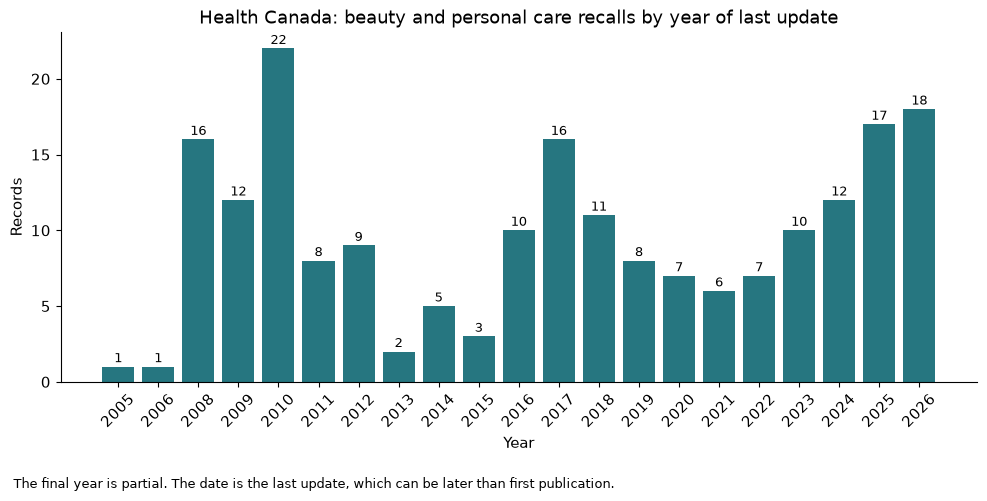

In [4]:
hc = pd.DataFrame(json.loads(HEALTH_CANADA_FILE.read_text(encoding='utf-8')))
required = {'NID', 'Title', 'Issue', 'Category', 'Last updated'}
if required - set(hc.columns):
    raise ValueError(f'Health Canada columns missing: {sorted(required - set(hc.columns))}')
hc['Title'] = hc['Title'].astype('string').str.replace('​', '', regex=False).str.strip()
hc['date'] = pd.to_datetime(hc['Last updated'], errors='coerce', utc=True)
hc['is_beauty'] = hc['Category'].astype('string').str.contains('Beauty and personal care', na=False)
hc_beauty = hc.loc[hc['is_beauty']].copy()
hc_beauty['issue_missing'] = hc_beauty['Issue'].astype('string').str.strip().fillna('').eq('')
window = hc_beauty['date'].between(pd.Timestamp('2012-01-01', tz='UTC'), pd.Timestamp('2023-09-30', tz='UTC'))

hc_profile = pd.Series({
    'All records': len(hc),
    'Repeated record ids': int(hc['NID'].duplicated().sum()),
    'Unusable dates': int(hc['date'].isna().sum()),
    'Beauty and personal care records': len(hc_beauty),
    'Beauty records with no hazard stated': int(hc_beauty['issue_missing'].sum()),
    'Beauty records, 2012 to September 2023': int(window.sum()),
    'Earliest beauty record': str(hc_beauty['date'].min().date()),
    'Latest beauty record': str(hc_beauty['date'].max().date()),
})
display(hc_profile.to_frame('value'))

hazard = hc_beauty.loc[~hc_beauty['issue_missing'], 'Issue'].str.split(' - ').str[0].value_counts().head(6)
display(hazard.rename_axis('first hazard stated').to_frame('beauty records'))

per_year = hc_beauty['date'].dt.year.value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(per_year.index.astype(str), per_year.values, color=INK)
for i, count in enumerate(per_year.values):
    ax.text(i, count + 0.3, str(count), ha='center', fontsize=9)
ax.set(title='Health Canada: beauty and personal care recalls by year of last update',
       xlabel='Year', ylabel='Records')
ax.tick_params(axis='x', rotation=45)
fig.text(0.02, 0.01, 'The final year is partial. The date is the last update, which can be later than first publication.', fontsize=9)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

### 4.2 openFDA drug recalls
In the United States, sunscreen, antiperspirant and hand sanitiser are regulated as drugs, so their recalls sit in this file and not in a cosmetics list. We look for personal care products and for recalls caused by benzene, a contaminant a shopper cannot smell or feel.

In [5]:
with ZipFile(FDA_RECALLS_FILE) as archive:
    fda_recalls = pd.DataFrame(json.loads(archive.read(archive.namelist()[0]))['results'])
required = {'recall_number', 'recall_initiation_date', 'product_description', 'reason_for_recall', 'recalling_firm'}
if required - set(fda_recalls.columns):
    raise ValueError(f'FDA recall columns missing: {sorted(required - set(fda_recalls.columns))}')
fda_recalls['date'] = pd.to_datetime(fda_recalls['recall_initiation_date'], format='%Y%m%d', errors='coerce')
personal_care = ('sunscreen|sun screen|antiperspirant|anti-perspirant|deodorant|hand sanitizer|'
                 'shampoo|conditioner|lotion|body wash|mouthwash|toothpaste|lip balm|moisturi')
fda_recalls['is_personal_care'] = fda_recalls['product_description'].astype('string').str.contains(personal_care, case=False, na=False)
fda_recalls['is_benzene'] = fda_recalls['reason_for_recall'].astype('string').str.contains('benzene', case=False, na=False)
in_window = fda_recalls['date'].between('2020-01-01', '2023-09-30')

fda_recall_profile = pd.Series({
    'All records': len(fda_recalls),
    'Repeated recall numbers': int(fda_recalls['recall_number'].duplicated().sum()),
    'Unusable dates': int(fda_recalls['date'].isna().sum()),
    'Missing product description': int(fda_recalls['product_description'].isna().sum()),
    'Personal care products (word match)': int(fda_recalls['is_personal_care'].sum()),
    'Benzene given as the reason': int(fda_recalls['is_benzene'].sum()),
    'Benzene, 2020 to September 2023': int((fda_recalls['is_benzene'] & in_window).sum()),
    'Earliest record': str(fda_recalls['date'].min().date()),
    'Latest record': str(fda_recalls['date'].max().date()),
})
display(fda_recall_profile.to_frame('value'))
display(fda_recalls.loc[fda_recalls['is_benzene'] & in_window, 'recalling_firm'].value_counts().head(8)
        .rename_axis('firm, benzene recalls 2020 to September 2023').to_frame('records'))

,value
All records,18010
Repeated recall numbers,0
Unusable dates,0
Missing product description,0
Personal care products (word match),558
Benzene given as the reason,114
"Benzene, 2020 to September 2023",74
Earliest record,2006-02-24
Latest record,2026-09-23


,records
"firm, benzene recalls 2020 to September 2023",
The Procter & Gamble Company,19
Scentsational Soaps & Candles Inc,19
Bayer Healthcare Pharmaceuticals Inc.,19
Beiersdorf Inc,5
TCP HRB ACQUISITON LLC,3
Unilever United States Inc.,2
"Johnson & Johnson Consumer, Inc.",2
"Edgewell Personal Care Brands, LLC",1


### 4.3 openFDA cosmetic adverse event reports
These are reports sent to the regulator, not reviews. A report does not show that the product caused the reaction. We check which reaction words are most common, because we want to borrow this vocabulary for labelling rules later.

,value
All reports,85511
Reports with no reaction term,0
Reports with no received date,0
Distinct reaction terms,2157
Reports naming a cancer term,"60,883 (71%)"
"Reports naming a skin, hair or irritation term","10,520 (12%)"
Earliest report received,2001-08-09
Latest report received,2025-08-29


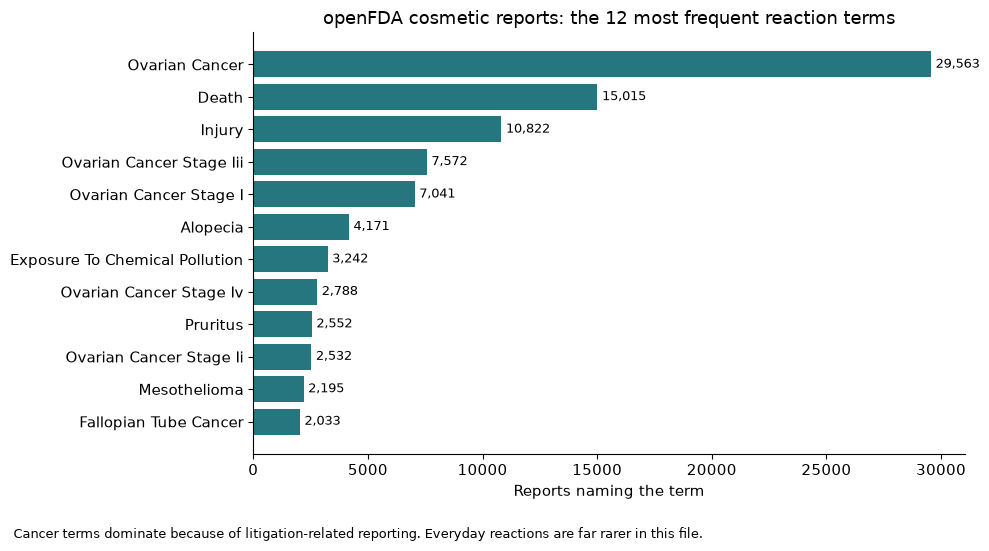

In [6]:
with ZipFile(FDA_EVENTS_FILE) as archive:
    events = json.loads(archive.read(archive.namelist()[0]))['results']
without_reactions = sum('reactions' not in report for report in events)
without_date = sum('initial_received_date' not in report for report in events)
reaction_counts = Counter(term for report in events if 'reactions' in report for term in report['reactions'])
cancer_terms = re.compile(r'cancer|mesothelioma|carcinoma|neoplasm', re.I)
skin_terms = re.compile(r'rash|pruritus|erythema|burning sensation|dermatitis|urticaria|blister|swelling|alopecia|irritation', re.I)
has_cancer = sum(any(cancer_terms.search(t) for t in report['reactions']) for report in events if 'reactions' in report)
has_skin = sum(any(skin_terms.search(t) for t in report['reactions']) for report in events if 'reactions' in report)
dates = pd.to_datetime(pd.Series([r['initial_received_date'] for r in events if 'initial_received_date' in r]),
                       format='%Y%m%d', errors='coerce')

events_profile = pd.Series({
    'All reports': len(events),
    'Reports with no reaction term': without_reactions,
    'Reports with no received date': without_date,
    'Distinct reaction terms': len(reaction_counts),
    'Reports naming a cancer term': f'{has_cancer:,} ({has_cancer / len(events):.0%})',
    'Reports naming a skin, hair or irritation term': f'{has_skin:,} ({has_skin / len(events):.0%})',
    'Earliest report received': str(dates.min().date()),
    'Latest report received': str(dates.max().date()),
})
display(events_profile.to_frame('value'))

top = pd.Series(dict(reaction_counts.most_common(12))).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(top.index, top.values, color=INK)
for y, count in enumerate(top.values):
    ax.text(count + 200, y, f'{count:,}', va='center', fontsize=9)
ax.set(title='openFDA cosmetic reports: the 12 most frequent reaction terms', xlabel='Reports naming the term')
fig.text(0.02, 0.01, 'Cancer terms dominate because of litigation-related reporting. Everyday reactions are far rarer in this file.', fontsize=9)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

**What this tells us.** The FDA report file is not a picture of everyday cosmetic reactions. Most of it is cancer reports linked to lawsuits. It is still useful as a word list (rash, pruritus, alopecia, burning sensation), but it must not be treated as ground truth or compared with review counts.

### 4.4 French recall notices and the product catalogue
These two files were examined in the earlier scoping notebook. Here we only confirm that the files in hand still give the same counts.

In [7]:
france = pd.read_csv(FRANCE_FILE, sep=';', encoding='utf-8-sig', dtype='string', keep_default_na=False, na_values=[''])
france.columns = france.columns.str.replace('﻿', '', regex=False).str.strip()
cosmetic_notices = france.loc[france['sous_categorie_produit'].str.strip().str.casefold().eq('cosmétiques').fillna(False)].drop_duplicates()
france_dates = pd.to_datetime(cosmetic_notices['date_publication'], utc=True, errors='coerce')
with gzip.open(CATALOGUE_FR_FILE, 'rt', encoding='utf-8') as handle:
    catalogue_rows = sum(1 for _ in handle) - 1

display(pd.Series({
    'French recall rows, all product types': len(france),
    'Distinct cosmetic notices': len(cosmetic_notices),
    'Cosmetic notices with no brand': int(cosmetic_notices['marque_produit'].isna().sum()),
    'Cosmetic notices with no consumer instruction': int(cosmetic_notices['conduites_a_tenir_par_le_consommateur'].isna().sum()),
    'First cosmetic notice': str(france_dates.min().date()),
    'Last cosmetic notice': str(france_dates.max().date()),
    'Open Beauty Facts catalogue rows': catalogue_rows,
}).to_frame('value'))

,value
"French recall rows, all product types",18730
Distinct cosmetic notices,296
Cosmetic notices with no brand,0
Cosmetic notices with no consumer instruction,5
First cosmetic notice,2021-04-20
Last cosmetic notice,2026-09-25
Open Beauty Facts catalogue rows,64237


## 5. The product catalogue and the recalled product lines
The Amazon catalogue is the index card for every product: its title, brand and how many ratings it has. We read it once to measure it and to find products whose title matches a recalled product line.

The 40 recalled lines below were picked by hand from the Health Canada and FDA files in sections 4.1 and 4.2. Each needs every listed phrase to appear in the product title. **A title match is a candidate, not a confirmed product**: size, batch and country are not checked.

In [8]:
# (label, phrases that must all appear in the title, recall date, source, hazard)
TARGETS = [
    ('Neutrogena Beach Defense spray', ['neutrogena', 'beach defense', 'spray'], '2021-07-14', 'FDA', 'benzene'),
    ('Coppertone Pure & Simple spray', ['coppertone', 'pure & simple', 'spray'], '2021-09-30', 'FDA', 'benzene'),
    ('Coppertone Sport Mineral spray', ['coppertone', 'sport', 'mineral', 'spray'], '2021-09-30', 'FDA', 'benzene'),
    ('Lotrimin AF spray', ['lotrimin', 'spray'], '2021-10-01', 'FDA', 'benzene'),
    ('Tinactin spray', ['tinactin', 'spray'], '2021-10-01', 'FDA', 'benzene'),
    ('Odor-Eaters spray powder', ['odor-eaters', 'spray'], '2021-11-17', 'FDA', 'benzene'),
    ('Secret dry spray', ['secret', 'dry spray'], '2021-11-23', 'FDA', 'benzene'),
    ('Old Spice Pure Sport spray', ['old spice', 'pure sport', 'spray'], '2021-11-23', 'FDA', 'benzene'),
    ('Old Spice Sweat Defense spray', ['old spice', 'sweat defense', 'spray'], '2021-11-23', 'FDA', 'benzene'),
    ('Sure aerosol antiperspirant', ['sure', 'aerosol', 'antiperspirant'], '2022-02-16', 'FDA', 'benzene'),
    ('Brut Classic spray', ['brut', 'classic', 'spray'], '2022-02-16', 'FDA', 'benzene'),
    ('Suave 24 Hour aerosol', ['suave', 'aerosol', 'antiperspirant'], '2022-03-30', 'FDA', 'benzene'),
    ('Banana Boat Hair & Scalp spray', ['banana boat', 'scalp'], '2022-07-29', 'FDA', 'benzene'),
    ('artnaturals hand sanitizer', ['artnaturals', 'hand sanitizer'], '2021-10-26', 'FDA', 'benzene'),
    ('Herbal Essences dry shampoo', ['herbal essences', 'dry shampoo'], '2021-12-20', 'Health Canada', 'benzene'),
    ('Pantene dry shampoo', ['pantene', 'dry shampoo'], '2021-12-20', 'Health Canada', 'benzene'),
    ('Dove dry shampoo', ['dove', 'dry shampoo'], '2022-10-18', 'Health Canada', 'benzene'),
    ('TRESemme dry shampoo', ['tresemm', 'dry shampoo'], '2022-10-18', 'Health Canada', 'benzene'),
    ('Bed Head dry shampoo', ['bed head', 'dry shampoo'], '2022-10-18', 'Health Canada', 'benzene'),
    ('Bioderma Sensibio H2O', ['bioderma', 'sensibio', 'h2o'], '2022-03-04', 'Health Canada', 'microbial'),
    ('Herbivore Pink Cloud cream', ['herbivore', 'pink cloud'], '2019-04-08', 'Health Canada', 'microbial'),
    ('Becca Light Shifter concealer', ['becca', 'light shifter'], '2020-06-23', 'Health Canada', 'microbial'),
    ('Method gel hand wash Sweet Water', ['method', 'hand wash', 'sweet water'], '2020-11-18', 'Health Canada', 'microbial'),
    ('Young Living Orange Blossom', ['young living', 'orange blossom'], '2019-06-19', 'Health Canada', 'microbial'),
    ('Saje Splish Splash baby wash', ['saje', 'splish splash'], '2018-07-12', 'Health Canada', 'microbial'),
    ('SeneGence hair balm', ['senegence', 'hair balm'], '2020-08-28', 'Health Canada', 'microbial'),
    ('Marcelle eye makeup remover pads', ['marcelle', 'remover', 'pads'], '2016-03-04', 'Health Canada', 'microbial'),
    ('Kiss My Face foaming soap', ['kiss my face', 'foaming'], '2014-04-17', 'Health Canada', 'microbial'),
    ('Honest baby powder', ['honest', 'baby powder'], '2017-02-21', 'Health Canada', 'microbial'),
    ('Aura Cacia Milk & Oat bath', ['aura cacia', 'oat'], '2016-09-29', 'Health Canada', 'microbial'),
    ('Equate daily moisturizing lotion', ['equate', 'daily moisturizing lotion'], '2021-07-27', 'Health Canada', 'microbial'),
    ('Benefit Gimme Brow', ['benefit', 'gimme brow'], '2017-11-15', 'Health Canada', 'chemical'),
    ('CHI Tea Tree blow dry primer', ['chi', 'tea tree', 'primer'], '2017-04-13', 'Health Canada', 'chemical'),
    ('KeraCare detangling shampoo', ['keracare', 'detangling shampoo'], '2018-01-16', 'Health Canada', 'other'),
    ('Beautycounter Volume & Shape shampoo', ['beautycounter', 'shampoo'], '2017-08-15', 'Health Canada', 'other'),
    ('Arbonne Fine Line eyeliner', ['arbonne', 'eyeliner'], '2016-06-24', 'Health Canada', 'other'),
    ('Vichy LiftActiv Peptide-C ampoules', ['vichy', 'liftactiv', 'ampoule'], '2022-07-13', 'Health Canada', 'laceration'),
    ('Cantu oil sheen conditioning spray', ['cantu', 'oil sheen'], '2023-07-13', 'Health Canada', 'labelling'),
    ('Sachajuan hairspray', ['sachajuan', 'hairspray'], '2023-07-13', 'Health Canada', 'labelling'),
    ('Matrix Vavoom freezing spray', ['matrix', 'vavoom', 'freezing'], '2019-06-12', 'Health Canada', 'labelling'),
]
targets = pd.DataFrame(TARGETS, columns=['line', 'phrases', 'recall_date', 'source', 'hazard'])
assert targets['line'].is_unique
print(len(targets), 'recalled product lines:', targets['hazard'].value_counts().to_dict())

40 recalled product lines: {'benzene': 19, 'microbial': 12, 'other': 3, 'labelling': 3, 'chemical': 2, 'laceration': 1}


In [9]:
CATALOGUE_SCAN = PROCESSED / 'amazon_catalogue_scan.json'
catalogue_sha = records.loc[records['file'].str.endswith('meta_Beauty_and_Personal_Care.jsonl.gz'), 'sha256'].item()
targets_sha = hashlib.sha256(json.dumps(TARGETS).encode()).hexdigest()


def scan_catalogue():
    stats = Counter()
    matches = {line: [] for line in targets['line']}
    with gzip.open(CATALOGUE_FILE, 'rt', encoding='utf-8') as handle:
        for raw_line in handle:
            item = json.loads(raw_line)
            stats['products'] += 1
            title = (item['title'] or '').lower()
            stats['no_title'] += not title.strip()
            stats['no_brand'] += not item['store']
            stats['no_ratings'] += not item['rating_number']
            stats['ratings_total'] += item['rating_number'] or 0
            for line, phrases in zip(targets['line'], targets['phrases']):
                if phrases[0] in title and all(p in title for p in phrases):
                    matches[line].append([item['parent_asin'], item['rating_number'] or 0])
    return {'source_sha256': catalogue_sha, 'targets_sha256': targets_sha, 'stats': dict(stats), 'matches': matches}


catalogue_scan = json.loads(CATALOGUE_SCAN.read_text()) if CATALOGUE_SCAN.is_file() else None
if (catalogue_scan is None or catalogue_scan['source_sha256'] != catalogue_sha
        or catalogue_scan['targets_sha256'] != targets_sha):
    started = time.time()
    catalogue_scan = scan_catalogue()
    CATALOGUE_SCAN.write_text(json.dumps(catalogue_scan))
    print(f'Catalogue read in {time.time() - started:.0f} seconds.')
else:
    print('Loaded the saved catalogue scan.')

c = catalogue_scan['stats']
display(pd.Series({
    'Products in the catalogue': f"{c['products']:,}",
    'Products with no title': f"{c['no_title']:,} ({c['no_title'] / c['products']:.1%})",
    'Products with no brand (store) field': f"{c['no_brand']:,} ({c['no_brand'] / c['products']:.1%})",
    'Ratings counted across all products': f"{c['ratings_total']:,}",
    'Recalled lines with at least one title match': f"{sum(bool(v) for v in catalogue_scan['matches'].values())} of {len(targets)}",
}).to_frame('value'))

Loaded the saved catalogue scan.


,value
Products in the catalogue,"1,028,914"
Products with no title,54 (0.0%)
Products with no brand (store) field,"50,713 (4.9%)"
Ratings counted across all products,"231,053,850"
Recalled lines with at least one title match,27 of 40


## 6. Read the reviews once
This is the big step. Imagine reading 23.9 million postcards and, for each one, ticking a few boxes: how many stars, what year, does it use a safety-related word, does it contain leftover web code. We keep the tallies, and we set aside two smaller piles for later weeks:

- **the candidate pile**: every review that uses at least one safety-related word;
- **a random pile** of 20,000 reviews that use none, so we can later check what the word list misses.

Both piles are stored in `data/processed`, which is never published. Reviewer names are replaced by a scrambled key.

**The word list is deliberately simple and was written before reading any reviews.** It is a net for catching candidates, not a detector. It catches "no irritation at all" as readily as "it irritated my skin", which is exactly why human labels are needed.

In [10]:
WORD_GROUPS = {
    'skin_reaction': r'\b(rash(es)?|hives|itch(y|ing|ed)?|blister(s|ed)?|swell(ing)?|swollen|allergic reaction|chemical burn|burn(ed|t|ing|s)? my (skin|face|scalp|eyes?|lips?))\b',
    'irritation': r'\birritat(ed|ion|ing|es)\b',
    'eye': r'\b(eye infection|pink ?eye|stye|eyes? (burn(ed|ing)?|sting(ing)?|swelled|swollen))\b',
    'hair_scalp': r'\b(hair (fell|falling|fall) out|hair loss|bald spots?|scalp (burn(ed|ing)?|sores?))\b',
    'smell_spoilage': r'\b(rancid|mold(y)?|mould(y)?|spoiled|rotten|smell(s|ed)? (bad|awful|terrible|horrible|off|sour|like chemicals?)|foul (odor|odour|smell))\b',
    'contamination': r'\b(contaminat(ed|ion)|bacteria(l)?|infection|expired|recall(ed)?)\b',
}
GROUP_LABELS = {'skin_reaction': 'Skin reaction', 'irritation': 'Irritation', 'eye': 'Eye',
                'hair_scalp': 'Hair and scalp', 'smell_spoilage': 'Smell and spoilage', 'contamination': 'Contamination'}
GROUP_PATTERNS = {name: re.compile(pattern, re.I) for name, pattern in WORD_GROUPS.items()}
ANY_PATTERN = re.compile('|'.join(f'(?:{pattern})' for pattern in WORD_GROUPS.values()), re.I)

REVIEW_SCAN = PROCESSED / 'amazon_review_scan.json'
CANDIDATES_FILE = PROCESSED / 'complaint_candidates.jsonl.gz'
RANDOM_FILE = PROCESSED / 'random_no_keyword_sample.jsonl.gz'
RANDOM_SIZE = 20_000
YEAR_MS = 365 * 86400 * 1000
reviews_sha = records.loc[records['file'].str.endswith('/Beauty_and_Personal_Care.jsonl.gz'), 'sha256'].item()
words_sha = hashlib.sha256(json.dumps(WORD_GROUPS).encode()).hexdigest()


def scan_reviews():
    rng = random.Random(SEED)
    tally = Counter()
    by_rating, hit_by_rating, by_year, hit_by_year, by_group = Counter(), Counter(), Counter(), Counter(), Counter()
    product_to_lines, cutoff = {}, {}
    for line, date in zip(targets['line'], targets['recall_date']):
        cutoff[line] = datetime.fromisoformat(date).replace(tzinfo=timezone.utc).timestamp() * 1000
        for product, _ in catalogue_scan['matches'][line]:
            product_to_lines.setdefault(product, []).append(line)
    before, last12, after = Counter(), Counter(), Counter()
    reservoir, seen_no_keyword = [], 0

    def keep(review, groups):
        key = hashlib.sha1(f"{review['user_id']}|{review['asin']}|{review['timestamp']}".encode()).hexdigest()[:16]
        return {'review_key': key, 'parent_asin': review['parent_asin'], 'rating': int(review['rating']),
                'timestamp': review['timestamp'], 'verified_purchase': review['verified_purchase'],
                'helpful_vote': review['helpful_vote'], 'groups': groups,
                'title': review['title'], 'text': review['text']}

    with gzip.open(REVIEWS_FILE, 'rt', encoding='utf-8') as handle, \
            gzip.open(CANDIDATES_FILE, 'wt', encoding='utf-8', compresslevel=5) as candidates:
        for raw_line in handle:
            review = json.loads(raw_line)
            text, title = review['text'], review['title']
            both = f'{title} {text}'
            rating = int(review['rating'])
            year = time.gmtime(review['timestamp'] // 1000).tm_year
            tally['reviews'] += 1
            by_rating[rating] += 1
            by_year[year] += 1
            tally['verified'] += review['verified_purchase']
            tally['words'] += both.count(' ') + 1
            if not text.strip():
                tally['empty_text'] += 1
            elif text.count(' ') < 2:
                tally['under_three_words'] += 1
            tally['html_entity'] += '&#' in both
            tally['line_break_tag'] += '<br' in both
            tally['video_placeholder'] += '[[VIDEOID' in both
            tally['non_ascii'] += not both.isascii()

            if review['parent_asin'] in product_to_lines:
                for line in product_to_lines[review['parent_asin']]:
                    if review['timestamp'] < cutoff[line]:
                        before[line] += 1
                        last12[line] += review['timestamp'] >= cutoff[line] - YEAR_MS
                    else:
                        after[line] += 1

            if ANY_PATTERN.search(both):
                groups = [name for name, pattern in GROUP_PATTERNS.items() if pattern.search(both)]
                tally['any_keyword'] += 1
                hit_by_rating[rating] += 1
                hit_by_year[year] += 1
                by_group.update(groups)
                candidates.write(json.dumps(keep(review, groups)) + '\n')
            else:
                seen_no_keyword += 1
                if len(reservoir) < RANDOM_SIZE:
                    reservoir.append(keep(review, []))
                else:
                    slot = rng.randrange(seen_no_keyword)
                    if slot < RANDOM_SIZE:
                        reservoir[slot] = keep(review, [])
            if tally['reviews'] % 5_000_000 == 0:
                print(f"  {tally['reviews']:,} reviews read")

    with gzip.open(RANDOM_FILE, 'wt', encoding='utf-8', compresslevel=5) as out:
        for row in reservoir:
            out.write(json.dumps(row) + '\n')
    return {'source_sha256': reviews_sha, 'words_sha256': words_sha, 'targets_sha256': targets_sha,
            'tally': dict(tally), 'by_group': dict(by_group),
            'by_rating': {str(k): v for k, v in sorted(by_rating.items())},
            'hit_by_rating': {str(k): v for k, v in sorted(hit_by_rating.items())},
            'by_year': {str(k): v for k, v in sorted(by_year.items())},
            'hit_by_year': {str(k): v for k, v in sorted(hit_by_year.items())},
            'before': dict(before), 'last12': dict(last12), 'after': dict(after)}


review_scan = json.loads(REVIEW_SCAN.read_text()) if REVIEW_SCAN.is_file() else None
fresh = (review_scan is not None and CANDIDATES_FILE.is_file() and RANDOM_FILE.is_file()
         and review_scan['source_sha256'] == reviews_sha and review_scan['words_sha256'] == words_sha
         and review_scan['targets_sha256'] == targets_sha)
if not fresh:
    started = time.time()
    review_scan = scan_reviews()
    REVIEW_SCAN.write_text(json.dumps(review_scan))
    print(f'Reviews read in {(time.time() - started) / 60:.1f} minutes.')
else:
    print('Loaded the saved review scan.')

t = review_scan['tally']
by_rating = pd.Series(review_scan['by_rating']).rename(index=int)
hit_by_rating = pd.Series(review_scan['hit_by_rating']).rename(index=int)
by_year = pd.Series(review_scan['by_year']).rename(index=int)
hit_by_year = pd.Series(review_scan['hit_by_year']).rename(index=int)
assert by_rating.sum() == t['reviews'] == by_year.sum()
assert hit_by_rating.sum() == t['any_keyword']
print(f"{t['reviews']:,} reviews, {t['any_keyword']:,} with at least one safety-related word.")

Loaded the saved review scan.
23,911,390 reviews, 614,203 with at least one safety-related word.


## 7. How much review data is there?

,value
Reviews,"23,911,390"
Verified purchase,"21,785,369 (91.1%)"
Five-star reviews,"15,463,216 (64.7%)"
One-star reviews,"2,840,878 (11.9%)"
Reviews with no text,"36,594 (0.15%)"
Average length in words,37.9
First year,2000
Last year,2023


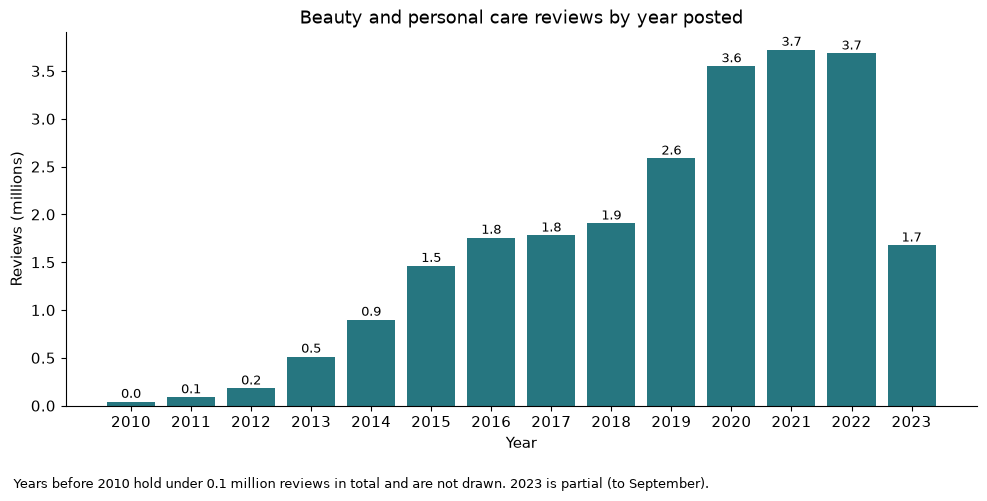

In [11]:
review_profile = pd.Series({
    'Reviews': f"{t['reviews']:,}",
    'Verified purchase': f"{t['verified']:,} ({t['verified'] / t['reviews']:.1%})",
    'Five-star reviews': f"{by_rating[5]:,} ({by_rating[5] / t['reviews']:.1%})",
    'One-star reviews': f"{by_rating[1]:,} ({by_rating[1] / t['reviews']:.1%})",
    'Reviews with no text': f"{t['empty_text']:,} ({t['empty_text'] / t['reviews']:.2%})",
    'Average length in words': f"{t['words'] / t['reviews']:.1f}",
    'First year': int(by_year.index.min()),
    'Last year': int(by_year.index.max()),
})
display(review_profile.to_frame('value'))

recent = by_year.loc[by_year.index >= 2010]
fig, ax = plt.subplots()
ax.bar(recent.index.astype(str), recent.values / 1e6, color=INK)
for i, count in enumerate(recent.values):
    ax.text(i, count / 1e6 + 0.04, f'{count / 1e6:.1f}', ha='center', fontsize=9)
ax.set(title='Beauty and personal care reviews by year posted', xlabel='Year', ylabel='Reviews (millions)')
fig.text(0.02, 0.01, 'Years before 2010 hold under 0.1 million reviews in total and are not drawn. 2023 is partial (to September).', fontsize=9)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

## 8. How often do reviews use a safety-related word?
Two questions, and they have different answers:

1. **Out of all one-star reviews, what share uses a safety word?** (And the same for each star level.)
2. **Out of all reviews that use a safety word, what share is five-star?**

The second one is the surprise.

,reviews,share_of_all_reviews_percent
word group,,
Skin reaction,264803,1.11
Irritation,188371,0.79
Smell and spoilage,104162,0.44
Contamination,48399,0.20
Hair and scalp,36581,0.15
Eye,7405,0.03


Any group: 614,203 reviews (2.57%). Groups overlap, so they sum to more.


,reviews,with_safety_word,share_with_safety_word_percent,share_of_all_safety_word_reviews_percent
stars,,,,
1,2840878,164625,5.8,26.8
2,1275031,53254,4.2,8.7
3,1715821,49821,2.9,8.1
4,2616444,63328,2.4,10.3
5,15463216,283175,1.8,46.1


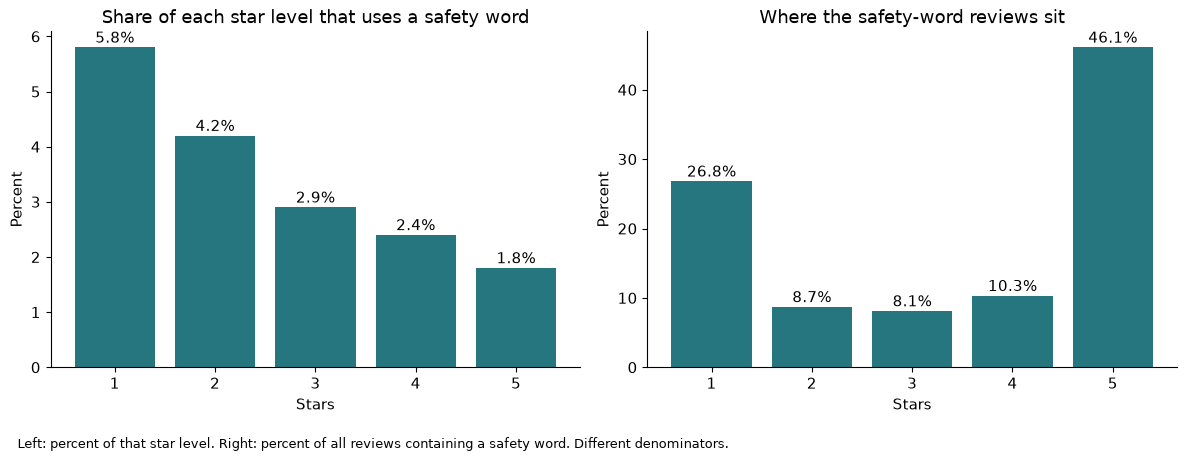

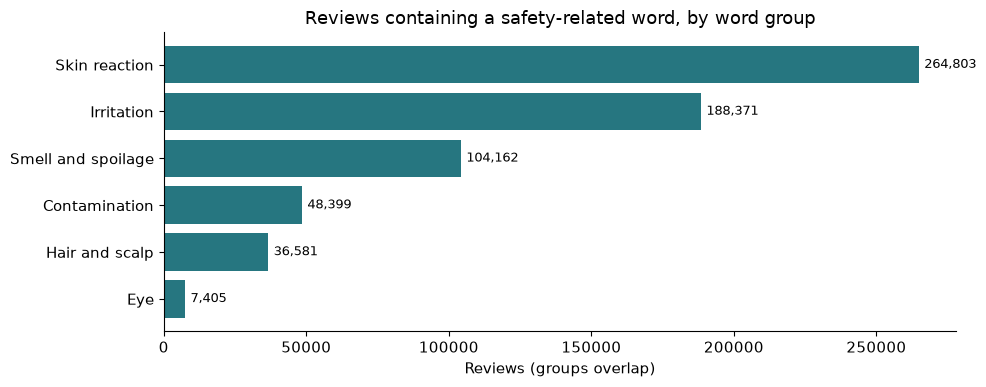

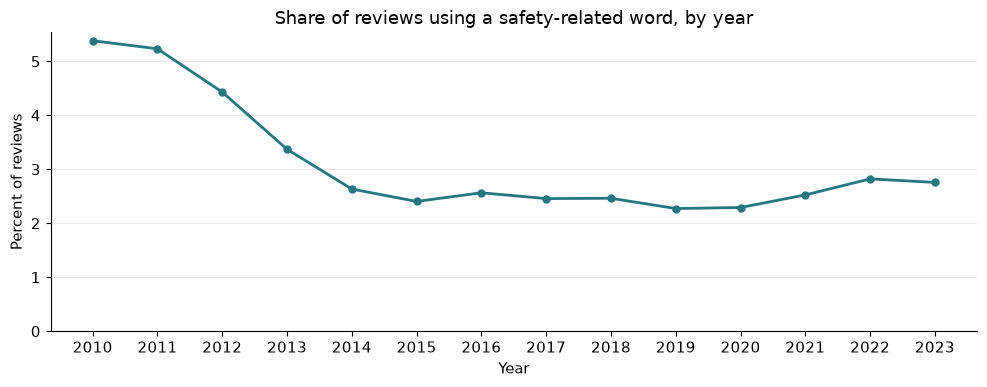

In [12]:
group_table = (pd.Series(review_scan['by_group']).rename(index=GROUP_LABELS).sort_values(ascending=False)
               .rename_axis('word group').to_frame('reviews'))
group_table['share_of_all_reviews_percent'] = (group_table['reviews'] / t['reviews'] * 100).round(2)
display(group_table)
print(f"Any group: {t['any_keyword']:,} reviews ({t['any_keyword'] / t['reviews']:.2%}). Groups overlap, so they sum to more.")

rating_table = pd.DataFrame({'reviews': by_rating, 'with_safety_word': hit_by_rating})
rating_table['share_with_safety_word_percent'] = (rating_table['with_safety_word'] / rating_table['reviews'] * 100).round(1)
rating_table['share_of_all_safety_word_reviews_percent'] = (rating_table['with_safety_word'] / t['any_keyword'] * 100).round(1)
display(rating_table.rename_axis('stars'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, column, title in [
        (axes[0], 'share_with_safety_word_percent', 'Share of each star level that uses a safety word'),
        (axes[1], 'share_of_all_safety_word_reviews_percent', 'Where the safety-word reviews sit')]:
    ax.bar(rating_table.index.astype(str), rating_table[column], color=INK)
    for i, value in enumerate(rating_table[column]):
        ax.text(i, value + rating_table[column].max() * 0.015, f'{value}%', ha='center')
    ax.set(title=title, xlabel='Stars', ylabel='Percent')
fig.text(0.02, 0.01, 'Left: percent of that star level. Right: percent of all reviews containing a safety word. Different denominators.', fontsize=9)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

groups_sorted = group_table['reviews'].iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(groups_sorted.index, groups_sorted.values, color=INK)
for y, count in enumerate(groups_sorted.values):
    ax.text(count + 2000, y, f'{count:,}', va='center', fontsize=9)
ax.set(title='Reviews containing a safety-related word, by word group', xlabel='Reviews (groups overlap)')
fig.tight_layout()
plt.show()

yearly_rate = (hit_by_year.reindex(recent.index).fillna(0) / recent * 100)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(yearly_rate.index.astype(str), yearly_rate.values, color=INK, linewidth=2, marker='o', markersize=5)
ax.set(title='Share of reviews using a safety-related word, by year', xlabel='Year', ylabel='Percent of reviews', ylim=(0, None))
ax.grid(axis='y', alpha=0.25)
fig.tight_layout()
plt.show()

**Reading the result.** One-star reviews use safety words about three times as often as five-star reviews. Yet because five-star reviews are so common, close to half of all safety-word reviews are five-star. Many of those are praise ("no irritation"). So neither the word list nor the star rating can stand in for a label. That is the case for hand labelling in Weeks 3 and 4.

## 8a. A first look inside the safety-word reviews
The scan saved two piles: every review that uses a safety word (the candidate pile) and 20,000 random reviews that use none. Comparing them is like comparing the letters a complaints desk receives with ordinary post: before reading any of them closely, we can already see whether they differ in length, tone and who wrote them.

### Which word groups carry praise and which carry complaints?

,"1 star, percent","2 star, percent","3 star, percent","4 star, percent","5 star, percent"
word group,,,,,
Smell and spoilage,48.1,13.6,10.8,8.0,19.5
Eye,41.2,12.2,10.4,8.5,27.6
Contamination,39.7,8.6,7.4,8.0,36.2
Skin reaction,26.5,8.5,7.7,9.2,48.1
Hair and scalp,23.8,6.0,6.3,11.7,52.3
Irritation,13.4,6.8,7.6,13.4,58.9


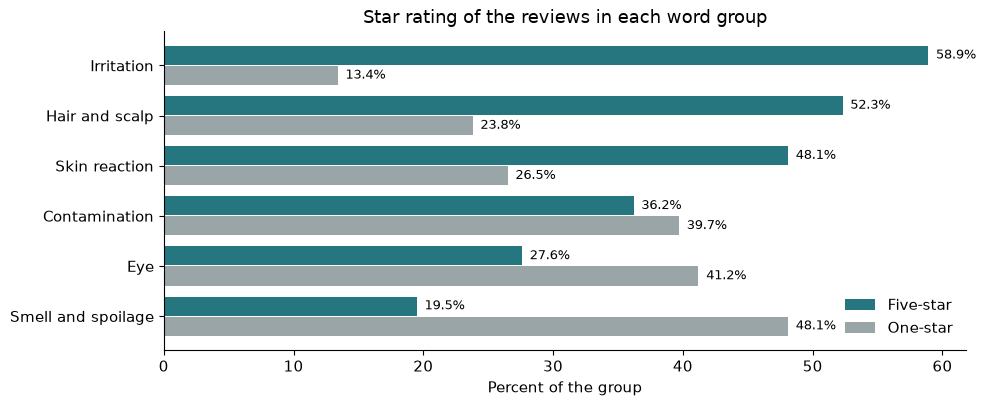

In [13]:
text_columns = {'review_key': 'string', 'parent_asin': 'string', 'title': 'string', 'text': 'string'}
candidates = pd.read_json(CANDIDATES_FILE, lines=True, dtype=text_columns, convert_dates=False)
random_sample = pd.read_json(RANDOM_FILE, lines=True, dtype=text_columns, convert_dates=False)
assert len(candidates) == t['any_keyword'] and len(random_sample) == RANDOM_SIZE

group_stars = pd.DataFrame({
    GROUP_LABELS[name]: candidates.loc[candidates['groups'].map(lambda g, name=name: name in g), 'rating'].value_counts(normalize=True)
    for name in WORD_GROUPS}).T.sort_index(axis=1).mul(100).round(1)
group_stars.columns = [f'{stars} star, percent' for stars in group_stars.columns]
group_stars = group_stars.sort_values('5 star, percent')
display(group_stars.rename_axis('word group'))

fig, ax = plt.subplots(figsize=(10, 4.2))
y = range(len(group_stars))
ax.barh([v + 0.2 for v in y], group_stars['5 star, percent'], height=0.38, color=INK, label='Five-star')
ax.barh([v - 0.2 for v in y], group_stars['1 star, percent'], height=0.38, color=GREY, label='One-star')
for v, (five, one) in enumerate(zip(group_stars['5 star, percent'], group_stars['1 star, percent'])):
    ax.text(five + 0.6, v + 0.2, f'{five}%', va='center', fontsize=9)
    ax.text(one + 0.6, v - 0.2, f'{one}%', va='center', fontsize=9)
ax.set_yticks(list(y), group_stars.index)
ax.set(title='Star rating of the reviews in each word group', xlabel='Percent of the group')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

**Reading the result.** The groups do not behave alike. Irritation words sit mostly in happy reviews, smell and spoilage words mostly in angry ones. One rule for all six groups would be wrong for most of them.

### Is the safety word being reported or denied?
"No irritation at all" contains a safety word and is praise. The check below looks for a negation cue (no, not, never, without, didn't and similar) up to three words before a safety word. It is a rough ruler, not a parser: it misses "irritation free" and wrongly catches "not only did it burn".

Negation cue before a safety word: 142,572 of 614,203 safety-word reviews (23.2%)


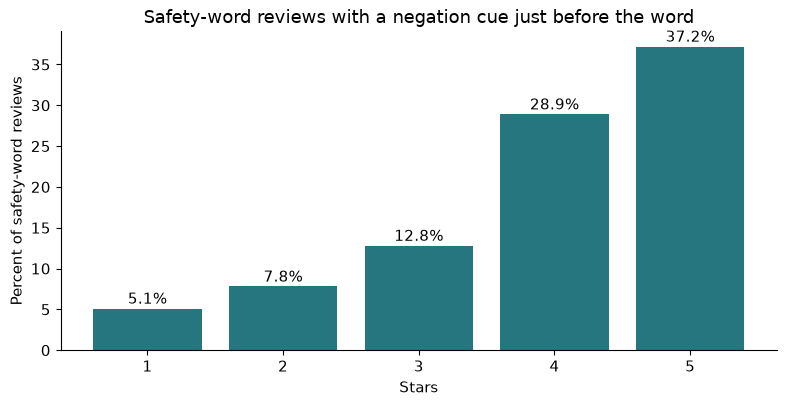

In [14]:
# ponytail: fixed three-word window; a dependency parse would be more exact, add it if the labelled pilot shows the rule is too crude
SAFETY_WORD = r'(?:rash(?:es)?|hives|itch(?:y|ing|ed)?|blisters?|swelling|swollen|allergic reaction|irritat(?:ed|ion|ing|es)|burn(?:ed|t|ing|s)?|rancid|mold(?:y)?|mould(?:y)?|infection|hair loss|breakouts?)'
NEGATION = (r"\b(?:no|not|never|without|zero|non|didn'?t|doesn'?t|don'?t|hasn'?t|haven'?t|won'?t|wasn'?t|isn'?t|free of)\b"
            r'(?:\W+\w+){0,3}?\W+' + SAFETY_WORD)
for phrase, expected in [('no irritation at all', True), ('it did not cause any rash', True),
                         ('gave me a rash', False), ('my skin was burning', False)]:
    assert bool(re.search(NEGATION, phrase, re.I)) is expected, phrase

candidate_text = candidates['title'].fillna('') + ' ' + candidates['text'].fillna('')
negated = candidate_text.str.contains(NEGATION, case=False, regex=True)
negation_by_rating = negated.groupby(candidates['rating']).mean().mul(100).round(1)
print(f'Negation cue before a safety word: {int(negated.sum()):,} of {len(candidates):,} safety-word reviews ({negated.mean():.1%})')

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(negation_by_rating.index.astype(str), negation_by_rating.values, color=INK)
for i, value in enumerate(negation_by_rating.values):
    ax.text(i, value + 0.6, f'{value}%', ha='center')
ax.set(title='Safety-word reviews with a negation cue just before the word', xlabel='Stars', ylabel='Percent of safety-word reviews')
fig.tight_layout()
plt.show()

**Reading the result.** The higher the star rating, the more often the safety word is being denied. So star rating and negation are both useful clues, and neither is a label: this is why Week 4 turns them into labelling rules and checks them against hand labels.

### Do safety-word reviews look different from ordinary reviews?

,Safety-word reviews,Random reviews with no safety word
Reviews,"614,203","20,000"
"Words, lower quartile",27,8
"Words, median",52,20
"Words, upper quartile",97,41
Mean star rating,3.4,4.14
"One-star, percent",26.8,11.1
"Five-star, percent",46.1,65.4
"At least one helpful vote, percent",43.9,25.8
"Verified purchase, percent",83.0,90.9


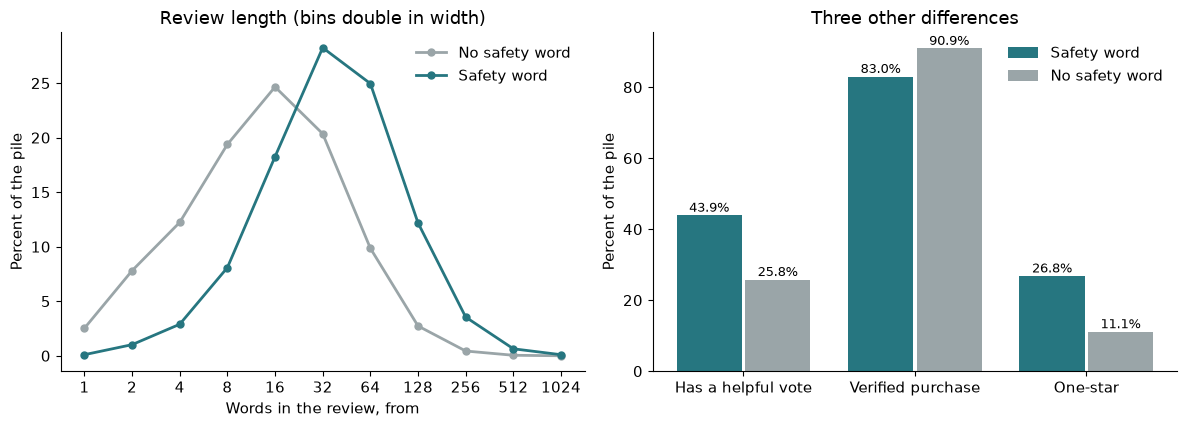

In [15]:
def describe_pile(pile):
    words = pile['text'].fillna('').str.count(' ').add(1)
    return pd.Series({
        'Reviews': f'{len(pile):,}',
        'Words, lower quartile': int(words.quantile(0.25)),
        'Words, median': int(words.median()),
        'Words, upper quartile': int(words.quantile(0.75)),
        'Mean star rating': round(pile['rating'].mean(), 2),
        'One-star, percent': round((pile['rating'] == 1).mean() * 100, 1),
        'Five-star, percent': round((pile['rating'] == 5).mean() * 100, 1),
        'At least one helpful vote, percent': round((pile['helpful_vote'] >= 1).mean() * 100, 1),
        'Verified purchase, percent': round(pile['verified_purchase'].mean() * 100, 1),
    }), words

candidate_stats, candidate_words = describe_pile(candidates)
random_stats, random_words = describe_pile(random_sample)
pile_compare = pd.DataFrame({'Safety-word reviews': candidate_stats, 'Random reviews with no safety word': random_stats})
display(pile_compare)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
bins = [1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 4096]
for words, colour, label in [(random_words, GREY, 'No safety word'), (candidate_words, INK, 'Safety word')]:
    share = pd.cut(words, bins, right=False).value_counts(normalize=True, sort=False) * 100
    axes[0].plot(range(len(share)), share.values, color=colour, linewidth=2, marker='o', markersize=5, label=label)
axes[0].set_xticks(range(len(bins) - 1), [str(b) for b in bins[:-1]])
axes[0].set(title='Review length (bins double in width)', xlabel='Words in the review, from', ylabel='Percent of the pile')
axes[0].legend(frameon=False)
measures = ['At least one helpful vote, percent', 'Verified purchase, percent', 'One-star, percent']
x = range(len(measures))
axes[1].bar([v - 0.2 for v in x], pile_compare.loc[measures, 'Safety-word reviews'].astype(float), width=0.38, color=INK, label='Safety word')
axes[1].bar([v + 0.2 for v in x], pile_compare.loc[measures, 'Random reviews with no safety word'].astype(float), width=0.38, color=GREY, label='No safety word')
for v, m in enumerate(measures):
    a, b = float(pile_compare.loc[m, 'Safety-word reviews']), float(pile_compare.loc[m, 'Random reviews with no safety word'])
    axes[1].text(v - 0.2, a + 1, f'{a}%', ha='center', fontsize=9)
    axes[1].text(v + 0.2, b + 1, f'{b}%', ha='center', fontsize=9)
axes[1].set_xticks(list(x), ['Has a helpful vote', 'Verified purchase', 'One-star'])
axes[1].set(title='Three other differences', ylabel='Percent of the pile')
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()

**Reading the result.** Safety-word reviews are longer, more often voted helpful and a little less often from a verified purchase. Length and helpful votes become candidate features for Week 4. The verified flag needs a sensitivity check, because unverified reviews are where fake complaints would hide.

### How are the safety-word reviews spread across products?
A rate over time can only be measured for a product that has enough of these reviews.

,safety-word reviews per product,products,share of catalogue,share of safety-word reviews they hold
0,At least 1,138833,13.49%,100.0%
1,At least 5,21766,2.12%,70.7%
2,At least 20,4627,0.45%,46.6%
3,At least 100,595,0.06%,21.7%


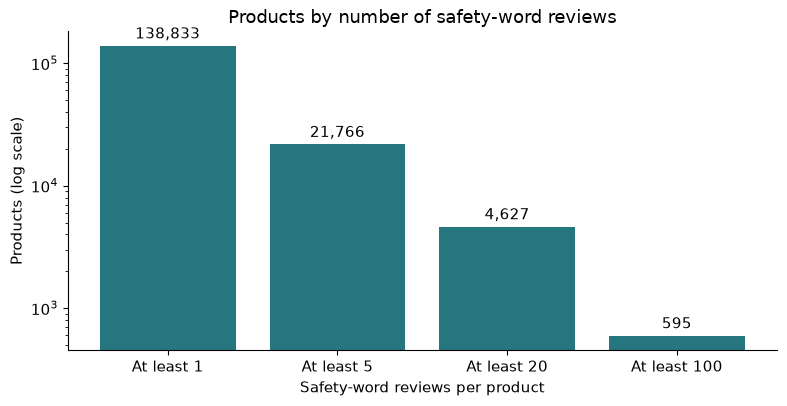

In [16]:
per_product = candidates['parent_asin'].value_counts()
spread = pd.DataFrame([
    [f'At least {n}', int((per_product >= n).sum()), f"{(per_product >= n).sum() / c['products']:.2%}",
     f'{per_product[per_product >= n].sum() / len(candidates):.1%}']
    for n in [1, 5, 20, 100]], columns=['safety-word reviews per product', 'products', 'share of catalogue', 'share of safety-word reviews they hold'])
display(spread)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(spread['safety-word reviews per product'], spread['products'], color=INK)
for i, count in enumerate(spread['products']):
    ax.text(i, count * 1.15, f'{count:,}', ha='center')
ax.set_yscale('log')
ax.set(title='Products by number of safety-word reviews', xlabel='Safety-word reviews per product', ylabel='Products (log scale)')
fig.tight_layout()
plt.show()

**Reading the result.** Most products with a safety-word review have only one or two. A few thousand have enough to chart over time. Any per-product monitoring in later weeks is limited to those.

## 9. Do recalled products have earlier reviews?
For the exploratory question about complaint rates before a recall (RQ4), a product line is only usable if people reviewed it before the recall date, ideally in the year before.

,line,source,hazard,recall_date,matched_products,reviews_before_recall,reviews_in_12_months_before,reviews_after_recall
0,Bioderma Sensibio H2O,Health Canada,microbial,2022-03-04,6,3016,368,449
1,Dove dry shampoo,Health Canada,benzene,2022-10-18,11,2062,241,17
2,Neutrogena Beach Defense spray,FDA,benzene,2021-07-14,5,695,193,236
3,Matrix Vavoom freezing spray,Health Canada,labelling,2019-06-12,4,78,47,274
4,Coppertone Sport Mineral spray,FDA,benzene,2021-09-30,3,79,44,7
5,Secret dry spray,FDA,benzene,2021-11-23,7,37,35,174
6,Banana Boat Hair & Scalp spray,FDA,benzene,2022-07-29,6,295,21,9
7,KeraCare detangling shampoo,Health Canada,other,2018-01-16,16,170,21,191
8,TRESemme dry shampoo,Health Canada,benzene,2022-10-18,16,588,18,9
9,Method gel hand wash Sweet Water,Health Canada,microbial,2020-11-18,11,23,17,14


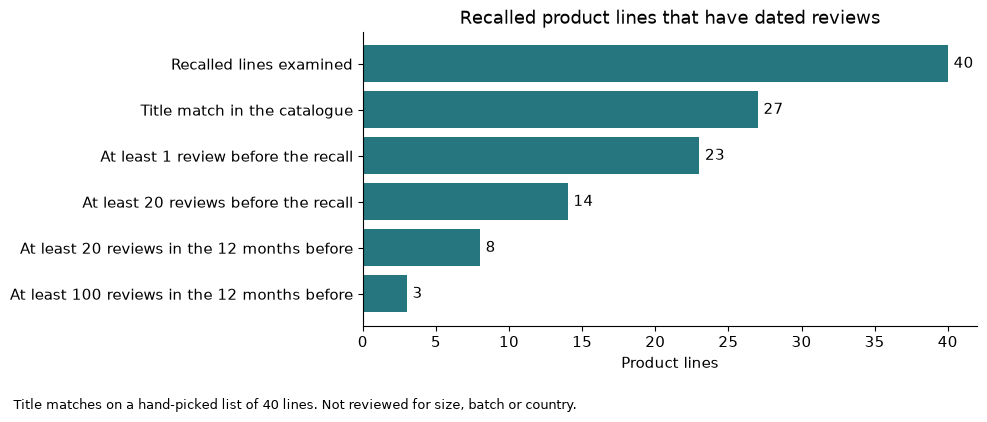

,lines with 20 or more reviews in the 12 months before
hazard,
benzene,5
labelling,1
microbial,1
other,1


In [17]:
overlap = targets[['line', 'source', 'hazard', 'recall_date']].copy()
overlap['matched_products'] = [len(catalogue_scan['matches'][line]) for line in overlap['line']]
for column in ['before', 'last12', 'after']:
    overlap[column] = [review_scan[column][line] if line in review_scan[column] else 0 for line in overlap['line']]
overlap = overlap.rename(columns={'before': 'reviews_before_recall', 'last12': 'reviews_in_12_months_before',
                                  'after': 'reviews_after_recall'})
overlap.to_csv(PROCESSED / 'recall_review_overlap.csv', index=False)
display(overlap.sort_values('reviews_in_12_months_before', ascending=False).head(15).reset_index(drop=True))

funnel = pd.Series({
    'Recalled lines examined': len(overlap),
    'Title match in the catalogue': int((overlap['matched_products'] > 0).sum()),
    'At least 1 review before the recall': int((overlap['reviews_before_recall'] >= 1).sum()),
    'At least 20 reviews before the recall': int((overlap['reviews_before_recall'] >= 20).sum()),
    'At least 20 reviews in the 12 months before': int((overlap['reviews_in_12_months_before'] >= 20).sum()),
    'At least 100 reviews in the 12 months before': int((overlap['reviews_in_12_months_before'] >= 100).sum()),
})
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(funnel.index[::-1], funnel.values[::-1], color=INK)
for y, count in enumerate(funnel.values[::-1]):
    ax.text(count + 0.4, y, str(count), va='center')
ax.set(title='Recalled product lines that have dated reviews', xlabel='Product lines')
fig.text(0.02, 0.01, 'Title matches on a hand-picked list of 40 lines. Not reviewed for size, batch or country.', fontsize=9)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

usable = overlap['reviews_in_12_months_before'] >= 20
display(overlap.loc[usable].groupby('hazard').size().rename('lines with 20 or more reviews in the 12 months before').to_frame())
lines_usable = int(usable.sum())

**Reading the result.** Few recalled lines have enough recent reviews to compare, and most of those are benzene recalls, which a shopper cannot perceive. RQ4 therefore stays a descriptive comparison plus a case study. No model of recalls will be built.

### 9.1 One recalled line, quarter by quarter
Counting lines is abstract, so here is one of them. Bioderma Sensibio H2O micellar water was recalled in Canada on 4 March 2022 for microbial contamination. The cell collects every review of the products whose titles match that line and asks: what would a quality analyst have had to read in the year before the recall? Only the date, star rating and a yes or no for "uses a safety word" are saved.

,reviews
Reviews of the matched products,3465
Before the recall date,3016
"Before the recall, using a safety word",242
In the 12 months before the recall,368
12 months before: one or two star,56
12 months before: using a safety word,42
12 months before: safety word and five-star,20
12 months before: safety word and one or two star,12


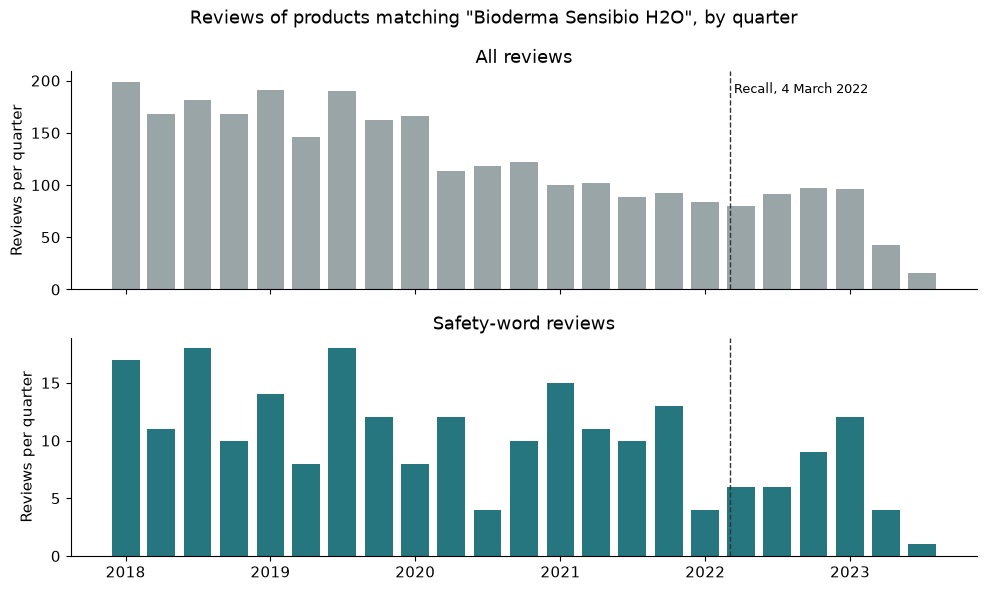

In [18]:
CASE_LINE, CASE_FILE = 'Bioderma Sensibio H2O', PROCESSED / 'case_line_reviews.csv'
case_recall = pd.Timestamp(targets.loc[targets['line'] == CASE_LINE, 'recall_date'].item())
if not CASE_FILE.exists():
    case_products = {product for product, _ in catalogue_scan['matches'][CASE_LINE]}
    rows = []
    with gzip.open(REVIEWS_FILE, 'rt', encoding='utf-8') as handle:
        for raw_line in handle:
            at = raw_line.find('"parent_asin": "')
            if raw_line[at + 16:at + 26] not in case_products:
                continue
            review = json.loads(raw_line)
            assert review['parent_asin'] in case_products
            rows.append((review['timestamp'], int(review['rating']),
                         bool(ANY_PATTERN.search(f"{review['title']} {review['text']}"))))
    pd.DataFrame(rows, columns=['timestamp', 'rating', 'safety_word']).to_csv(CASE_FILE, index=False)
case_line = pd.read_csv(CASE_FILE)
case_line['date'] = pd.to_datetime(case_line['timestamp'], unit='ms')
before_recall = case_line[case_line['date'] < case_recall]
year_before = before_recall[before_recall['date'] >= case_recall - pd.DateOffset(years=1)]
low_star = year_before['rating'] <= 2

display(pd.Series({
    'Reviews of the matched products': len(case_line),
    'Before the recall date': len(before_recall),
    'Before the recall, using a safety word': int(before_recall['safety_word'].sum()),
    'In the 12 months before the recall': len(year_before),
    '12 months before: one or two star': int(low_star.sum()),
    '12 months before: using a safety word': int(year_before['safety_word'].sum()),
    '12 months before: safety word and five-star': int((year_before['safety_word'] & (year_before['rating'] == 5)).sum()),
    '12 months before: safety word and one or two star': int((year_before['safety_word'] & low_star).sum()),
}).to_frame('reviews'))

quarterly = (case_line[case_line['date'] >= '2018-01-01'].set_index('date')
             .resample('QS')['safety_word'].agg(['size', 'sum']).rename(columns={'size': 'all reviews', 'sum': 'safety-word reviews'}))
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, column, colour in [(axes[0], 'all reviews', GREY), (axes[1], 'safety-word reviews', INK)]:
    ax.bar(quarterly.index, quarterly[column], width=70, color=colour)
    ax.axvline(case_recall, color='#333333', linestyle='--', linewidth=1)
    ax.set(ylabel='Reviews per quarter', title=column.capitalize())
axes[0].text(case_recall, axes[0].get_ylim()[1] * 0.9, ' Recall, 4 March 2022', fontsize=9)
fig.suptitle(f'Reviews of products matching "{CASE_LINE}", by quarter')
fig.tight_layout()
plt.show()

**Reading the result.** Reading only the low-star reviews misses most of the reviews that use a safety word, and searching for safety words returns mostly five-star praise for a product sold for sensitive skin. The quarterly count of safety-word reviews shows no visible rise before the recall. That is an honest null from a crude ruler: the title match is unreviewed, the recall covered specific Canadian lots and these are US buyers. It shows why RQ4 needs labelled complaints and stays exploratory.

## 10. Cleaning the data will need
While reading the reviews we also counted the messy bits: leftover web code, empty reviews, very short ones. Each row below becomes a cleaning rule in Week 3.

In [19]:
repeated_text = int(candidates.duplicated(['parent_asin', 'title', 'text']).sum())
repeated_key = int(candidates['review_key'].duplicated().sum())
recalled_only = int((candidates['groups'].map(lambda g: g == ['contamination'])
                     & candidates['text'].str.contains(r'\brecall(?:ed)?\b', case=False, regex=True)
                     & ~candidates['text'].str.contains(r'contaminat|bacteria|infection|expired', case=False, regex=True)).sum())

share = lambda count, total=t['reviews']: f'{count:,} ({count / total:.2%})'
cleaning_needs = pd.DataFrame([
    ['Review has no text', share(t['empty_text']), 'Exclude from labelling; keep the count'],
    ['Review text under three words', share(t['under_three_words']), 'Keep; too short to describe a reaction, expect label No'],
    ['HTML character codes such as &#34;', share(t['html_entity']), 'Decode to plain characters in a cleaned copy'],
    ['Line break tags (<br />)', share(t['line_break_tag']), 'Replace with a space in the cleaned copy'],
    ['Video placeholders ([[VIDEOID:...]])', share(t['video_placeholder']), 'Remove the placeholder; keep the review'],
    ['Characters outside plain ASCII (emoji, accents, other scripts)', share(t['non_ascii']), 'Keep; measure non-English share in Week 3'],
    ['Same product, title and text repeated (candidate pile)', share(repeated_text, len(candidates)), 'Keep one copy for labelling'],
    ['Repeated review key (candidate pile)', share(repeated_key, len(candidates)), 'Investigate before using the key as an identifier'],
    ['Matched only on the word "recall" (candidate pile)', share(recalled_only, len(candidates)), 'Word also means "remember"; tighten or drop the pattern'],
], columns=['issue', 'reviews affected', 'planned handling'])
display(cleaning_needs)

,issue,reviews affected,planned handling
0,Review has no text,"36,594 (0.15%)",Exclude from labelling; keep the count
1,Review text under three words,"1,649,925 (6.90%)","Keep; too short to describe a reaction, expect label No"
2,HTML character codes such as &#34;,"217,524 (0.91%)",Decode to plain characters in a cleaned copy
3,Line break tags (<br />),"1,680,889 (7.03%)",Replace with a space in the cleaned copy
4,Video placeholders ([[VIDEOID:...]]),"200,283 (0.84%)",Remove the placeholder; keep the review
5,"Characters outside plain ASCII (emoji, accents, other scripts)","4,035,847 (16.88%)",Keep; measure non-English share in Week 3
6,"Same product, title and text repeated (candidate pile)","6,260 (1.02%)",Keep one copy for labelling
7,Repeated review key (candidate pile),"6,066 (0.99%)",Investigate before using the key as an identifier
8,"Matched only on the word ""recall"" (candidate pile)","4,401 (0.72%)","Word also means ""remember""; tighten or drop the pattern"


## 11. Data quality and relevance, source by source
One table, built from the numbers measured above. **Relevance** is a judgement about fit for our problem; the other columns are measurements.

In [20]:
quality = pd.DataFrame([
    {'source': 'Amazon reviews', 'rows': t['reviews'],
     'completeness': f"{1 - t['empty_text'] / t['reviews']:.2%} have text",
     'uniqueness': f'{repeated_text:,} repeated texts among {len(candidates):,} candidates',
     'timeliness': f'{int(by_year.index.min())} to September 2023, static',
     'validity': f"{t['verified'] / t['reviews']:.1%} verified purchase; some fake and AI-written reviews expected",
     'relevance': 'High: the only large source of customer wording'},
    {'source': 'Amazon catalogue', 'rows': c['products'],
     'completeness': f"{1 - c['no_brand'] / c['products']:.1%} have a brand field",
     'uniqueness': 'One row per parent product', 'timeliness': 'Static, to September 2023',
     'validity': 'Seller-entered titles; brand spelling varies',
     'relevance': 'High: needed to group reviews by product'},
    {'source': 'Health Canada recalls', 'rows': len(hc),
     'completeness': f"{1 - hc_beauty['issue_missing'].mean():.0%} of beauty records state a hazard",
     'uniqueness': f"{int(hc['NID'].duplicated().sum())} repeated ids",
     'timeliness': f"Latest beauty record {hc_beauty['date'].max().date()}", 'validity': 'Official; date is last update',
     'relevance': 'Medium: right hazards, different country'},
    {'source': 'openFDA drug recalls', 'rows': len(fda_recalls),
     'completeness': f"{fda_recalls['product_description'].notna().mean():.0%} have a product description",
     'uniqueness': f"{int(fda_recalls['recall_number'].duplicated().sum())} repeated recall numbers",
     'timeliness': f"Latest record {fda_recalls['date'].max().date()}", 'validity': 'Official; free-text product names',
     'relevance': 'Medium: same market, mostly imperceptible hazards'},
    {'source': 'openFDA cosmetic reports', 'rows': len(events),
     'completeness': f'{1 - without_reactions / len(events):.1%} have a reaction term',
     'uniqueness': 'One row per report', 'timeliness': f'Latest report {dates.max().date()}, frozen',
     'validity': f'Unverified; {has_cancer / len(events):.0%} name a cancer term',
     'relevance': 'Low to medium: vocabulary only'},
    {'source': 'French recall notices', 'rows': len(cosmetic_notices),
     'completeness': f"{cosmetic_notices['conduites_a_tenir_par_le_consommateur'].notna().mean():.0%} have consumer instructions",
     'uniqueness': 'Distinct notices after removing exact repeats',
     'timeliness': f'Latest cosmetic notice {france_dates.max().date()}', 'validity': 'Official',
     'relevance': 'Low for the main problem; kept for RQ5'},
    {'source': 'Open Beauty Facts', 'rows': catalogue_rows, 'completeness': 'Names missing for many products (earlier notebook)',
     'uniqueness': 'One row per barcode', 'timeliness': 'Snapshot of 2 October 2026', 'validity': 'Volunteer-entered',
     'relevance': 'Low for the main problem; kept for RQ5'},
])
quality['rows'] = quality['rows'].map('{:,}'.format)
quality.to_csv(PROCESSED / 'data_quality_matrix.csv', index=False)
display(quality)

,source,rows,completeness,uniqueness,timeliness,validity,relevance
0,Amazon reviews,"23,911,390",99.85% have text,"6,260 repeated texts among 614,203 candidates","2000 to September 2023, static",91.1% verified purchase; some fake and AI-written reviews expected,High: the only large source of customer wording
1,Amazon catalogue,"1,028,914",95.1% have a brand field,One row per parent product,"Static, to September 2023",Seller-entered titles; brand spelling varies,High: needed to group reviews by product
2,Health Canada recalls,"34,212",60% of beauty records state a hazard,0 repeated ids,Latest beauty record 2026-09-21,Official; date is last update,"Medium: right hazards, different country"
3,openFDA drug recalls,"18,010",100% have a product description,0 repeated recall numbers,Latest record 2026-09-23,Official; free-text product names,"Medium: same market, mostly imperceptible hazards"
4,openFDA cosmetic reports,"85,511",100.0% have a reaction term,One row per report,"Latest report 2025-08-29, frozen",Unverified; 71% name a cancer term,Low to medium: vocabulary only
5,French recall notices,296,98% have consumer instructions,Distinct notices after removing exact repeats,Latest cosmetic notice 2026-09-25,Official,Low for the main problem; kept for RQ5
6,Open Beauty Facts,"64,237",Names missing for many products (earlier notebook),One row per barcode,Snapshot of 2 October 2026,Volunteer-entered,Low for the main problem; kept for RQ5


## 12. How the data tests each hypothesis, and the exploration plan
Nothing here is run yet. This is the plan the Week 2 report describes and Weeks 4 to 6 carry out.

In [21]:
hypothesis_map = pd.DataFrame([
    ['H1', 'Two annotators agree on what a safety complaint is', 'Labelled reviews (pilot of 50, then 200 double-labelled)',
     'safety_complaint from annotator A and B', "Cohen's kappa with the confusion table", 'At least 0.70'],
    ['H2', 'A classifier beats the word list', 'Frozen labelled test set',
     'Review text, safety_complaint', 'Average precision, precision, recall; bootstrap interval of the difference', 'Interval excludes zero'],
    ['H3', 'Rule-made labels can replace most hand labels', 'Candidate pile and random pile; FDA reaction terms',
     'Labelling-rule outputs, safety_complaint', 'F1 on the same frozen test set', 'Within 0.05 of the hand-label model'],
    ['H4', 'Complaint rates rise before a recall (exploratory)', 'Reviews of recalled lines; recall dates',
     'Complaint rate per product and period', "Fisher's exact test per line, reported descriptively", f'Only {lines_usable} lines qualify'],
    ['H5', 'Brand and size matching traces products correctly (exploratory)', 'French notices and Open Beauty Facts',
     'Brand, name, quantity, barcode', 'Share of reviewed cases with the right notice first', 'Summary of earlier scoping'],
], columns=['hypothesis', 'claim', 'data used', 'key variables', 'statistic or test', 'decision rule'])
display(hypothesis_map)

eda_plan = pd.DataFrame([
    ['Review volume and length', 'Counts, median, quartiles', 'Bar chart by year; histogram of length (log scale)', 'pandas, matplotlib'],
    ['Star rating mix', 'Proportions', 'Bar chart', 'pandas, matplotlib'],
    ['Complaint rate by star rating', 'Proportion with a Wilson interval', 'Bar chart with interval marks', 'SciPy, matplotlib'],
    ['Complaint rate by product category', 'Proportion; chi-square test of independence', 'Sorted horizontal bars', 'SciPy, seaborn'],
    ['Complaint types', 'Counts and shares of labelled complaints', 'Horizontal bars', 'pandas, matplotlib'],
    ['Review length, complaint against non-complaint', 'Mann-Whitney U test', 'Box plot', 'SciPy, seaborn'],
    ['Words that separate complaints from praise', 'Log-odds ratio of word counts', 'Ranked word table', 'scikit-learn'],
    ['Negation near safety words', 'Share of safety-word reviews with a negation cue', 'Stacked bar by label', 'pandas, matplotlib'],
    ['Verified against unverified reviews', "Difference in proportions; Fisher's exact test", 'Paired bars', 'SciPy, matplotlib'],
    ['Complaint rate over time for recalled lines', 'Monthly rate with review count', 'Line chart with recall date marked', 'pandas, matplotlib'],
], columns=['what we look at', 'statistics', 'chart', 'libraries'])
display(eda_plan)

,hypothesis,claim,data used,key variables,statistic or test,decision rule
0,H1,Two annotators agree on what a safety complaint is,"Labelled reviews (pilot of 50, then 200 double-labelled)",safety_complaint from annotator A and B,Cohen's kappa with the confusion table,At least 0.70
1,H2,A classifier beats the word list,Frozen labelled test set,"Review text, safety_complaint","Average precision, precision, recall; bootstrap interval of the difference",Interval excludes zero
2,H3,Rule-made labels can replace most hand labels,Candidate pile and random pile; FDA reaction terms,"Labelling-rule outputs, safety_complaint",F1 on the same frozen test set,Within 0.05 of the hand-label model
3,H4,Complaint rates rise before a recall (exploratory),Reviews of recalled lines; recall dates,Complaint rate per product and period,"Fisher's exact test per line, reported descriptively",Only 8 lines qualify
4,H5,Brand and size matching traces products correctly (exploratory),French notices and Open Beauty Facts,"Brand, name, quantity, barcode",Share of reviewed cases with the right notice first,Summary of earlier scoping


,what we look at,statistics,chart,libraries
0,Review volume and length,"Counts, median, quartiles",Bar chart by year; histogram of length (log scale),"pandas, matplotlib"
1,Star rating mix,Proportions,Bar chart,"pandas, matplotlib"
2,Complaint rate by star rating,Proportion with a Wilson interval,Bar chart with interval marks,"SciPy, matplotlib"
3,Complaint rate by product category,Proportion; chi-square test of independence,Sorted horizontal bars,"SciPy, seaborn"
4,Complaint types,Counts and shares of labelled complaints,Horizontal bars,"pandas, matplotlib"
5,"Review length, complaint against non-complaint",Mann-Whitney U test,Box plot,"SciPy, seaborn"
6,Words that separate complaints from praise,Log-odds ratio of word counts,Ranked word table,scikit-learn
7,Negation near safety words,Share of safety-word reviews with a negation cue,Stacked bar by label,"pandas, matplotlib"
8,Verified against unverified reviews,Difference in proportions; Fisher's exact test,Paired bars,"SciPy, matplotlib"
9,Complaint rate over time for recalled lines,Monthly rate with review count,Line chart with recall date marked,"pandas, matplotlib"


## 13. Labelling guide and the 50-review pilot
A model can only be judged against labels that people agree on. Before labelling hundreds of reviews, two people label the same 50 and compare. If they disagree a lot, the guide is unclear and gets fixed first, which is much cheaper than relabelling later.

This cell writes the guide (it contains made-up examples only, so it is safe to publish) and draws the pilot:

- 30 reviews from the candidate pile, 5 from each word group;
- 10 reviews at random that use no safety word;
- 10 one or two star reviews that use no safety word.

Each annotator gets a sheet with the review and empty label columns. **Star rating and group are hidden** so they cannot sway the label. The sheets contain review text, so they stay in `data/processed`, which is never published. Existing sheets are never overwritten.

In [22]:
GUIDELINE = '''# Annotation guideline, version 0.1 (draft for the pilot)

## The one question

Does the reviewer say that **this product, as received or used,** caused a physical reaction, or showed spoilage, contamination or a hazardous defect?

## Labels

| Column | Allowed values | Notes |
|---|---|---|
| safety_complaint | yes, no, unclear | Always filled |
| complaint_type | skin_reaction, eye, hair_scalp, spoilage_contamination, packaging_injury, other | Only when safety_complaint is yes; choose the main one |
| severity_cue | none, discomfort, medical_attention | What the reviewer wrote; do not infer |
| experienced_by | reviewer, someone_else, not_stated | Second-hand reports are kept but marked |
| notes | free text | Optional; say why if the case was hard |

## Label yes when

- The reviewer describes a rash, burn, sting, swelling, hives, blisters, itching, hair loss or an eye reaction after using this product.
- The product arrived or became mouldy, rancid, separated, discoloured or foul-smelling in a way the reviewer treats as gone off.
- The reviewer reports contamination, a broken seal with signs of use, or an expired product.
- The packaging or applicator caused an injury.

## Label no when

- The safety word is negated ("no irritation", "did not burn").
- The product relieved the condition ("my itchy scalp is gone").
- The complaint is about a different product ("my old one gave me a rash").
- The reviewer simply dislikes the scent, colour or texture.
- The problem is delivery, price, size or that it did not work.
- The word is used in another sense ("I recalled using it before").

## Label unclear when

- The reviewer mentions an effect but does not connect it to the product.
- The text is too short or garbled to tell.

## Constructed examples (not quotations)

| Example | Label |
|---|---|
| "Two days in, my cheeks came up in a red, itchy rash." | yes, skin_reaction, discomfort |
| "Opened the jar and there were dark spots growing on top." | yes, spoilage_contamination, none |
| "It stung my eyes and they were swollen next morning, had to see a doctor." | yes, eye, medical_attention |
| "Gentle, no irritation even on sensitive skin." | no |
| "My scalp used to itch constantly and this fixed it." | no |
| "Far too sweet a scent for me." | no |
| "My skin felt odd afterwards but it might be the weather." | unclear |

## Rules for annotators

- Label from the text alone. Star rating and product name are hidden on purpose.
- Do not look the product up.
- Do not copy review text anywhere outside the labelling sheet.
- Skip any review you would rather not read and write "skipped" in notes.
'''
(LABELS / 'annotation_guideline.md').write_text(GUIDELINE, encoding='utf-8')

LABEL_COLUMNS = ['safety_complaint', 'complaint_type', 'severity_cue', 'experienced_by', 'notes']
SHEETS = {name: ANNOTATION / f'pilot_50_annotator_{name}.csv' for name in ['A', 'B']}
PILOT_KEY = ANNOTATION / 'pilot_50_key.csv'

if not PILOT_KEY.is_file():
    usable_candidates = candidates.loc[candidates['text'].str.strip().ne('')].drop_duplicates(['parent_asin', 'title', 'text'])
    picked, used_products = [], set()
    for position, group in enumerate(WORD_GROUPS):
        pool = usable_candidates.loc[usable_candidates['groups'].map(lambda g: group in g)
                                     & ~usable_candidates['parent_asin'].isin(used_products)]
        chosen = pool.drop_duplicates('parent_asin').sample(5, random_state=SEED + position).assign(stratum=f'keyword_{group}')
        used_products.update(chosen['parent_asin'])
        picked.append(chosen)
    plain = random_sample.loc[random_sample['text'].str.strip().ne('')
                              & ~random_sample['parent_asin'].isin(used_products)].drop_duplicates('parent_asin')
    random_ten = plain.sample(10, random_state=SEED).assign(stratum='random_no_keyword')
    low_star = plain.loc[plain['rating'].le(2) & ~plain['review_key'].isin(random_ten['review_key'])]
    picked += [random_ten, low_star.sample(10, random_state=SEED + 1).assign(stratum='low_star_no_keyword')]
    pilot = pd.concat(picked).sample(frac=1, random_state=SEED).reset_index(drop=True)
    assert len(pilot) == 50 and pilot['review_key'].is_unique and pilot['parent_asin'].is_unique
    pilot[['review_key', 'stratum', 'rating']].to_csv(PILOT_KEY, index=False)
    sheet = pilot[['review_key', 'title', 'text']].copy()
    for column in LABEL_COLUMNS:
        sheet[column] = ''
    for path in SHEETS.values():
        if path.is_file():
            raise FileExistsError(f'{path.name} exists without its key file. Resolve by hand; labels are never overwritten.')
        sheet.to_csv(path, index=False)
    print('Pilot drawn. Sheets written for annotators A and B.')
else:
    print('Pilot already drawn; existing sheets left untouched.')

pilot_key = pd.read_csv(PILOT_KEY)
display(pilot_key['stratum'].value_counts().rename_axis('stratum').to_frame('reviews in the pilot'))
print('Guide:', (LABELS / 'annotation_guideline.md').relative_to(PROJECT_DIR))
print('Sheets:', ', '.join(str(p.relative_to(PROJECT_DIR)) for p in SHEETS.values()))

Pilot already drawn; existing sheets left untouched.


,reviews in the pilot
stratum,
low_star_no_keyword,10
random_no_keyword,10
keyword_skin_reaction,5
keyword_irritation,5
keyword_contamination,5
keyword_eye,5
keyword_hair_scalp,5
keyword_smell_spoilage,5


Guide: data/labels/annotation_guideline.md
Sheets: data/processed/annotation/pilot_50_annotator_A.csv, data/processed/annotation/pilot_50_annotator_B.csv


### 13.1 Agreement between the two annotators
Cohen's kappa measures how much two people agree beyond what luck alone would produce. 0 means no better than chance and 1 means perfect agreement. By convention 0.61 to 0.80 is called substantial.

This cell reports the result once both sheets are filled in. Until then it says how many labels are still missing.

In [23]:
ALLOWED = {'yes', 'no', 'unclear'}
labels = {}
for name, path in SHEETS.items():
    sheet = pd.read_csv(path, dtype='string', keep_default_na=False)
    labels[name] = sheet.set_index('review_key')['safety_complaint'].str.strip().str.lower()
    unexpected = set(labels[name]) - ALLOWED - {''}
    if unexpected:
        raise ValueError(f'Annotator {name} used labels outside the guide: {sorted(unexpected)}')
filled = {name: int(series.ne('').sum()) for name, series in labels.items()}
pilot_kappa = None
pilot_complaint_share = None

if all(count == 50 for count in filled.values()):
    a, b = labels['A'], labels['B'].reindex(labels['A'].index)
    pilot_kappa = cohen_kappa_score(a, b, labels=sorted(ALLOWED))
    print(f"Cohen's kappa on the safety_complaint label: {pilot_kappa:.2f} (50 reviews)")
    display(pd.crosstab(a.rename('annotator A'), b.rename('annotator B')))
    keyword_keys = pilot_key.loc[pilot_key['stratum'].str.startswith('keyword_'), 'review_key']
    pilot_complaint_share = float(a.reindex(keyword_keys).eq('yes').mean())
    print(f'Annotator A labelled {pilot_complaint_share:.0%} of the 30 keyword reviews as a complaint.')
else:
    print(f"Pilot labelling pending. Filled so far: annotator A {filled['A']} of 50, annotator B {filled['B']} of 50.")

Pilot labelling pending. Filled so far: annotator A 0 of 50, annotator B 0 of 50.


## 14. Dataset feasibility checkpoint
The thresholds were fixed on 11 October 2026, before these counts were made in the notebook. F1 to F5 decide the core study. F6 decides only the exploratory recall question.

In [24]:
reviews_with_text = t['reviews'] - t['empty_text']
status = lambda met: 'Met' if met else 'Not met'
checkpoint = pd.DataFrame([
    ['F1', 'Dated beauty reviews with text, held locally', 'At least 500,000', f'{reviews_with_text:,}', status(reviews_with_text >= 500_000)],
    ['F2', 'Keyword-enriched pool to sample from', 'At least 5,000', f"{t['any_keyword']:,}", status(t['any_keyword'] >= 5_000)],
    ['F3', 'Genuine complaints among keyword reviews in the pilot', 'At least 10%',
     'Pending pilot' if pilot_complaint_share is None else f'{pilot_complaint_share:.0%}',
     'Pending' if pilot_complaint_share is None else status(pilot_complaint_share >= 0.10)],
    ['F4', 'Annotator agreement in the 50-review pilot', 'Kappa at least 0.60',
     'Pending pilot' if pilot_kappa is None else f'{pilot_kappa:.2f}',
     'Pending' if pilot_kappa is None else status(pilot_kappa >= 0.60)],
    ['F5', 'Expected complaints in the 1,000-review sample', 'At least 100',
     'Pending pilot' if pilot_complaint_share is None else f'About {480 * pilot_complaint_share:.0f} from the keyword stratum alone',
     'Pending' if pilot_complaint_share is None else status(480 * pilot_complaint_share >= 100)],
    ['F6', 'Recalled lines with 20 or more reviews in the 12 months before recall', 'At least 20',
     f'{lines_usable} of {len(overlap)}', status(lines_usable >= 20)],
], columns=['id', 'criterion', 'threshold', 'observed', 'status'])
checkpoint.to_csv(PROCESSED / 'feasibility_checkpoint.csv', index=False)
display(checkpoint)

core = checkpoint.loc[checkpoint['id'].isin(['F1', 'F2', 'F3', 'F4', 'F5']), 'status']
if core.eq('Met').all():
    decision = 'Go: the core study (RQ1 to RQ3) proceeds to the main annotation round.'
elif core.eq('Not met').any():
    decision = 'Revise: a core criterion is not met. Fix the guideline or word list and repeat the pilot once.'
else:
    decision = 'Provisional go: the data criteria are met; the two pilot criteria are still pending.'
display(Markdown(f'**Core study:** {decision}\n\n**RQ4:** '
                 + ('proceeds as planned.' if lines_usable >= 20 else
                    'F6 is not met, so RQ4 is limited to a descriptive comparison and a case study.')))

,id,criterion,threshold,observed,status
0,F1,"Dated beauty reviews with text, held locally","At least 500,000","23,874,796",Met
1,F2,Keyword-enriched pool to sample from,"At least 5,000","614,203",Met
2,F3,Genuine complaints among keyword reviews in the pilot,At least 10%,Pending pilot,Pending
3,F4,Annotator agreement in the 50-review pilot,Kappa at least 0.60,Pending pilot,Pending
4,F5,"Expected complaints in the 1,000-review sample",At least 100,Pending pilot,Pending
5,F6,Recalled lines with 20 or more reviews in the 12 months before recall,At least 20,8 of 40,Not met


**Core study:** Provisional go: the data criteria are met; the two pilot criteria are still pending.

**RQ4:** F6 is not met, so RQ4 is limited to a descriptive comparison and a case study.

## 15. What goes into the Week 2 report
The cell below gathers the headline numbers in one place so the report can quote them without retyping.

In [25]:
summary = pd.Series({
    'Sources assessed': len(register),
    'Sources rejected': int(register['decision'].eq('Rejected').sum()),
    'Files fingerprinted': len(records),
    'Amazon reviews': f"{t['reviews']:,}",
    'Amazon products': f"{c['products']:,}",
    'Reviews with a safety-related word': f"{t['any_keyword']:,} ({t['any_keyword'] / t['reviews']:.2%})",
    'Share of safety-word reviews that are five-star': f"{hit_by_rating[5] / t['any_keyword']:.1%}",
    'Safety-word rate, one-star against five-star': f"{hit_by_rating[1] / by_rating[1]:.1%} against {hit_by_rating[5] / by_rating[5]:.1%}",
    'Safety-word reviews with a negation cue': f'{negated.mean():.1%} overall; {negation_by_rating[5]}% of five-star, {negation_by_rating[1]}% of one-star',
    'Median words, safety-word against other reviews': f"{candidate_stats['Words, median']} against {random_stats['Words, median']}",
    'Products with a safety-word review': f"{len(per_product):,} of {c['products']:,}; {int((per_product >= 20).sum()):,} with 20 or more",
    'Case line, reviews in the 12 months before recall': f"{len(year_before)}; {int(year_before['safety_word'].sum())} use a safety word",
    'Health Canada beauty recalls': len(hc_beauty),
    'FDA benzene recalls, 2020 to September 2023': int((fda_recalls['is_benzene'] & in_window).sum()),
    'FDA cosmetic reports naming a cancer term': f'{has_cancer / len(events):.0%}',
    'Recalled lines usable for RQ4': f'{lines_usable} of {len(overlap)}',
    'Pilot reviews drawn': len(pilot_key),
    'Pilot labels filled (A, B)': f"{filled['A']}, {filled['B']}",
})
display(summary.to_frame('value'))

,value
Sources assessed,14
Sources rejected,4
Files fingerprinted,8
Amazon reviews,"23,911,390"
Amazon products,"1,028,914"
Reviews with a safety-related word,"614,203 (2.57%)"
Share of safety-word reviews that are five-star,46.1%
"Safety-word rate, one-star against five-star",5.8% against 1.8%
Safety-word reviews with a negation cue,"23.2% overall; 37.2% of five-star, 5.1% of one-star"
"Median words, safety-word against other reviews",52 against 20


## Limits of this week's work

- Every review figure describes one US marketplace, in English, up to September 2023.
- The word list is a sampling net, not a detector. Its counts include negations and unrelated uses, and it misses complaints phrased in other words.
- The negation check is a three-word window, so its percentages are approximate.
- The comparison pile is a random 20,000 reviews with no safety word, not the whole file.
- Recall matches are title matches on a hand-picked list of 40 lines. They are not confirmed products.
- Reviews carry no batch number, so nothing here ties a review to a recalled lot.
- The FDA dashboards were not downloaded because no stable bulk link was found.
- No model was trained and no label has been assigned by a person yet.